In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split, GridSearchCV    # Train test Split and Grid Search
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

import statsmodels.api as SM
from sklearn import metrics
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import statsmodels.api as SM



from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score
)

import warnings
warnings.filterwarnings('ignore')

from IPython.core.display import display, HTML
display(HTML('<style>.container { width:90% !important; }<\style>'))

In [2]:
df = pd.read_excel('C:/Users/rohit.a/Downloads/GREATLEARNING/CAPSTONE PROJECT/Cricket Win/Sports Data1.xlsx')  


In [3]:
df.tail()

,Game_number,Result,Avg_team_Age,Match_light_type,Match_format,Bowlers_in_team,Wicket_keeper_in_team,All_rounder_in_team,First_selection,Opponent,...,Max_run_scored_1over,Max_wicket_taken_1over,Extra_bowls_bowled,Min_run_given_1over,Min_run_scored_1over,Max_run_given_1over,extra_bowls_opponent,player_highest_run,Players_scored_zero,player_highest_wicket
2925,Game_2926,Win,30.0,Day,T20,3.0,1,4.0,Batting,South Africa,...,15.0,3,8.0,0,3.0,6.0,3,50.0,3,2
2926,Game_2927,Win,30.0,Day,ODI,4.0,1,3.0,Bowling,Kenya,...,14.0,4,8.0,2,3.0,6.0,2,52.0,2,1
2927,Game_2928,Win,30.0,Day and Night,ODI,4.0,1,3.0,Bowling,Pakistan,...,14.0,4,10.0,2,4.0,10.0,2,80.0,3,2
2928,Game_2929,Win,30.0,Day,ODI,4.0,1,3.0,Batting,Kenya,...,14.0,2,20.0,2,3.0,6.0,3,98.0,3,1
2929,Game_2930,Win,30.0,Day,ODI,4.0,1,3.0,Batting,Kenya,...,12.0,4,4.0,5,3.0,6.0,3,62.0,1,1


In [4]:
df.head()

,Game_number,Result,Avg_team_Age,Match_light_type,Match_format,Bowlers_in_team,Wicket_keeper_in_team,All_rounder_in_team,First_selection,Opponent,...,Max_run_scored_1over,Max_wicket_taken_1over,Extra_bowls_bowled,Min_run_given_1over,Min_run_scored_1over,Max_run_given_1over,extra_bowls_opponent,player_highest_run,Players_scored_zero,player_highest_wicket
0,Game_1,Loss,18.0,Day,ODI,3.0,1,3.0,Bowling,Srilanka,...,13.0,3,0.0,2,3.0,6.0,0,54.0,3,1
1,Game_2,Win,24.0,Day,T20,3.0,1,4.0,Batting,Zimbabwe,...,12.0,1,0.0,0,3.0,6.0,0,69.0,2,1
2,Game_3,Loss,24.0,Day and Night,T20,3.0,1,2.0,Bowling,Zimbabwe,...,14.0,4,0.0,0,3.0,6.0,0,69.0,3,1
3,Game_4,Win,24.0,NaN,ODI,2.0,1,2.0,Bowling,Kenya,...,15.0,4,0.0,2,3.0,6.0,0,73.0,3,1
4,Game_5,Loss,24.0,Night,ODI,1.0,1,3.0,Bowling,Srilanka,...,12.0,4,0.0,0,3.0,6.0,0,80.0,3,1


In [5]:
# Remove '_' (startswith) from column headers where present
for col in df.columns:
    if col.startswith('_'):
        df.rename(columns={col: col[1:]}, inplace=True)
        

In [6]:
columns = ['Players_scored_zero', 'player_highest_wicket']

for col in columns:
    df[col] = df[col].replace('Three', 3)

In [7]:
df['Match_format'].value_counts()

ODI      1865
T20       864
Test      125
20-20       6
Name: Match_format, dtype: int64

In [8]:
df['Match_format'] = df['Match_format'].replace('20-20', 'T20')

# Now count the unique values in the 'Match_format' column
counts = df['Match_format'].value_counts()

print(counts)

ODI     1865
T20      870
Test     125
Name: Match_format, dtype: int64


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Game_number             2930 non-null   object 
 1   Result                  2930 non-null   object 
 2   Avg_team_Age            2833 non-null   float64
 3   Match_light_type        2878 non-null   object 
 4   Match_format            2860 non-null   object 
 5   Bowlers_in_team         2848 non-null   float64
 6   Wicket_keeper_in_team   2930 non-null   int64  
 7   All_rounder_in_team     2890 non-null   float64
 8   First_selection         2871 non-null   object 
 9   Opponent                2894 non-null   object 
 10  Season                  2868 non-null   object 
 11  Audience_number         2849 non-null   float64
 12  Offshore                2866 non-null   object 
 13  Max_run_scored_1over    2902 non-null   float64
 14  Max_wicket_taken_1over  2930 non-null   

In [10]:
df.drop(columns=['Game_number', 'Wicket_keeper_in_team'], inplace=True)

In [11]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Result,2930,2,Win,2457,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Avg_team_Age,2833.0,NaN,NaN,NaN,29.242852,2.26423,12.0,30.0,30.0,30.0,70.0
Match_light_type,2878,3,Day,2041,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Match_format,2860,3,ODI,1865,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Bowlers_in_team,2848.0,NaN,NaN,NaN,2.913624,1.023907,1.0,2.0,3.0,4.0,5.0
All_rounder_in_team,2890.0,NaN,NaN,NaN,2.722491,1.092699,1.0,2.0,3.0,4.0,4.0
First_selection,2871,3,Bowling,1722,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Opponent,2894,9,South Africa,640,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Season,2868,3,Rainy,1309,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Audience_number,2849.0,NaN,NaN,NaN,46267.960688,48599.581459,7063.0,20363.0,34349.0,57876.0,1399930.0


In [12]:
null_values_sum = df.isnull().sum()

print(null_values_sum)

Result                     0
Avg_team_Age              97
Match_light_type          52
Match_format              70
Bowlers_in_team           82
All_rounder_in_team       40
First_selection           59
Opponent                  36
Season                    62
Audience_number           81
Offshore                  64
Max_run_scored_1over      28
Max_wicket_taken_1over     0
Extra_bowls_bowled        29
Min_run_given_1over        0
Min_run_scored_1over      27
Max_run_given_1over       34
extra_bowls_opponent       0
player_highest_run        28
Players_scored_zero        0
player_highest_wicket      0
dtype: int64


In [13]:
df = df[df['First_selection'].str.lower().isin(['batting', 'bowling'])]

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 2860 entries, 0 to 2929
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Result                  2860 non-null   object 
 1   Avg_team_Age            2763 non-null   float64
 2   Match_light_type        2808 non-null   object 
 3   Match_format            2791 non-null   object 
 4   Bowlers_in_team         2778 non-null   float64
 5   All_rounder_in_team     2821 non-null   float64
 6   First_selection         2860 non-null   object 
 7   Opponent                2824 non-null   object 
 8   Season                  2798 non-null   object 
 9   Audience_number         2780 non-null   float64
 10  Offshore                2797 non-null   object 
 11  Max_run_scored_1over    2832 non-null   float64
 12  Max_wicket_taken_1over  2860 non-null   int64  
 13  Extra_bowls_bowled      2844 non-null   float64
 14  Min_run_given_1over     2860 non-null   

In [15]:
mode = df['Match_light_type'].mode()[0]
df['Match_light_type'].fillna(mode, inplace=True)

In [16]:
# Missing Value Treatment
columns = ['Match_format', 'First_selection', 'Opponent', 'Offshore', 'Season']

for column in columns:
    mode = df[column].mode()[0]
    df[column].fillna(mode, inplace=True)

print(df)

     Result  Avg_team_Age Match_light_type Match_format  Bowlers_in_team  \
0      Loss          18.0              Day          ODI              3.0   
1       Win          24.0              Day          T20              3.0   
2      Loss          24.0    Day and Night          T20              3.0   
3       Win          24.0              Day          ODI              2.0   
4      Loss          24.0            Night          ODI              1.0   
...     ...           ...              ...          ...              ...   
2925    Win          30.0              Day          T20              3.0   
2926    Win          30.0              Day          ODI              4.0   
2927    Win          30.0    Day and Night          ODI              4.0   
2928    Win          30.0              Day          ODI              4.0   
2929    Win          30.0              Day          ODI              4.0   

      All_rounder_in_team First_selection      Opponent  Season  \
0                   

In [17]:
# Assuming df is your DataFrame and the columns have missing values
columns = ['Avg_team_Age', 'Bowlers_in_team', 'Audience_number', 'All_rounder_in_team','Extra_bowls_bowled','Min_run_scored_1over','player_highest_run','Max_run_given_1over','Max_run_scored_1over']

for col in columns:
    median = df[col].median()
    df[col].fillna(median, inplace=True)

In [18]:
df_na = df.isna().sum()
df_na[df_na.values > 0].sort_values(ascending=False)

Series([], dtype: int64)

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 2860 entries, 0 to 2929
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Result                  2860 non-null   object 
 1   Avg_team_Age            2860 non-null   float64
 2   Match_light_type        2860 non-null   object 
 3   Match_format            2860 non-null   object 
 4   Bowlers_in_team         2860 non-null   float64
 5   All_rounder_in_team     2860 non-null   float64
 6   First_selection         2860 non-null   object 
 7   Opponent                2860 non-null   object 
 8   Season                  2860 non-null   object 
 9   Audience_number         2860 non-null   float64
 10  Offshore                2860 non-null   object 
 11  Max_run_scored_1over    2860 non-null   float64
 12  Max_wicket_taken_1over  2860 non-null   int64  
 13  Extra_bowls_bowled      2860 non-null   float64
 14  Min_run_given_1over     2860 non-null   

In [20]:
df['Match_format'].value_counts()

ODI     1893
T20      846
Test     121
Name: Match_format, dtype: int64

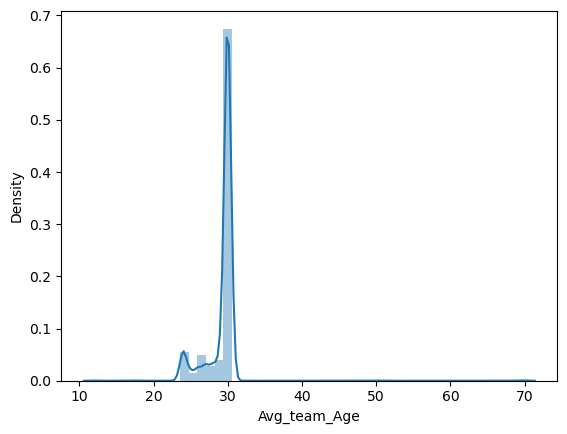

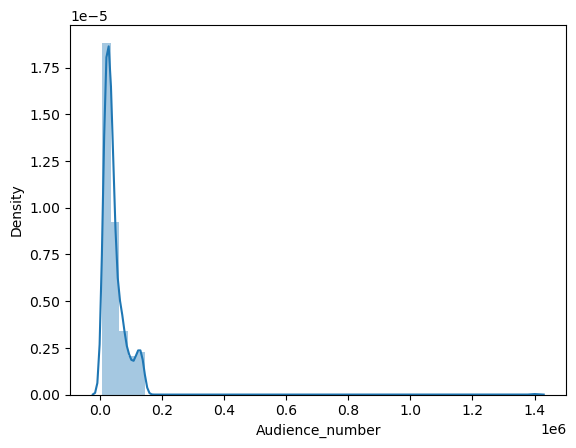

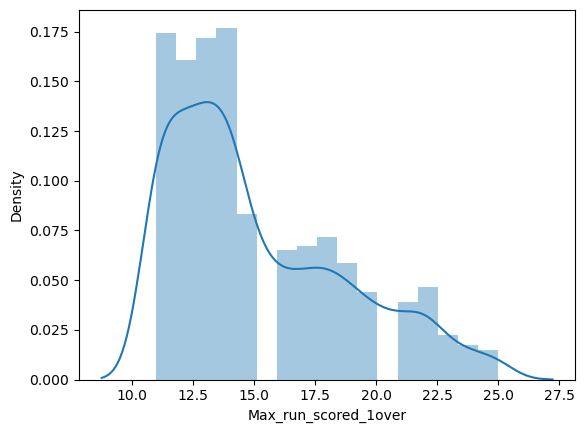

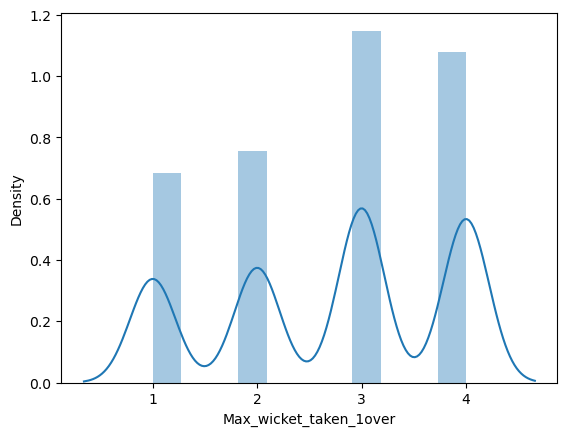

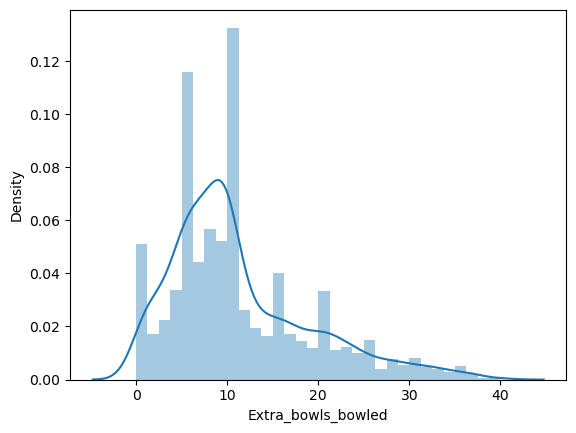

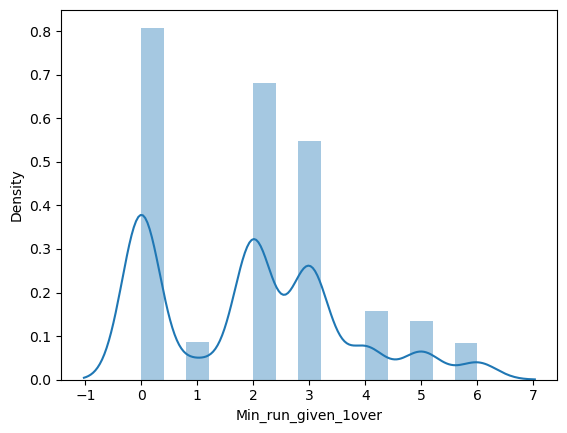

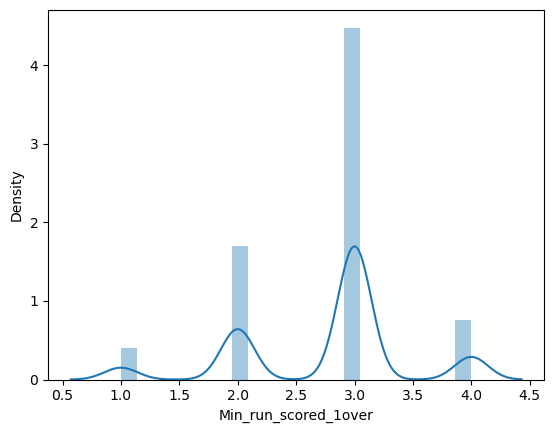

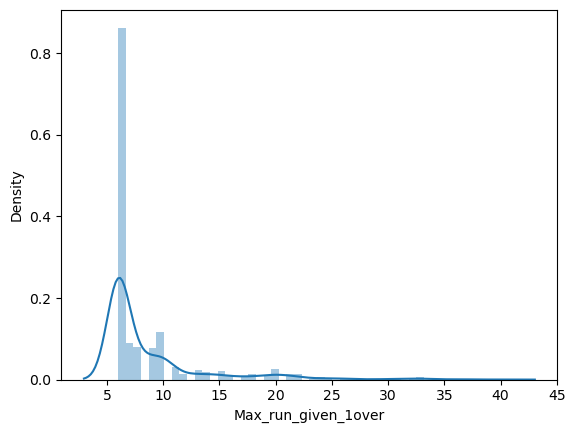

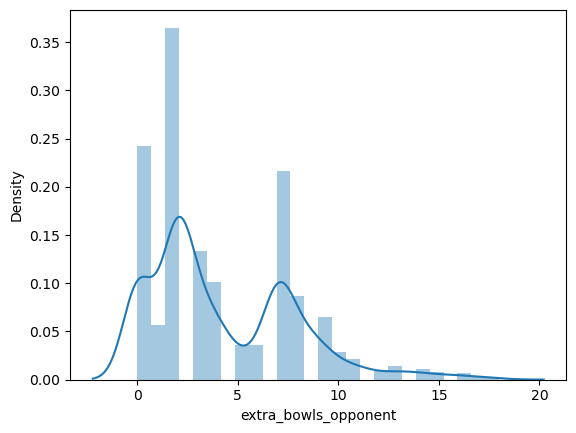

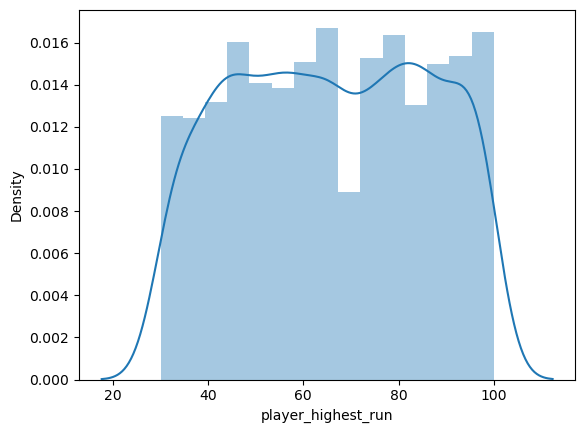

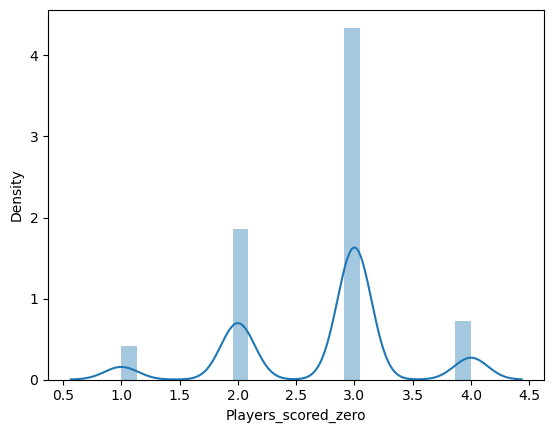

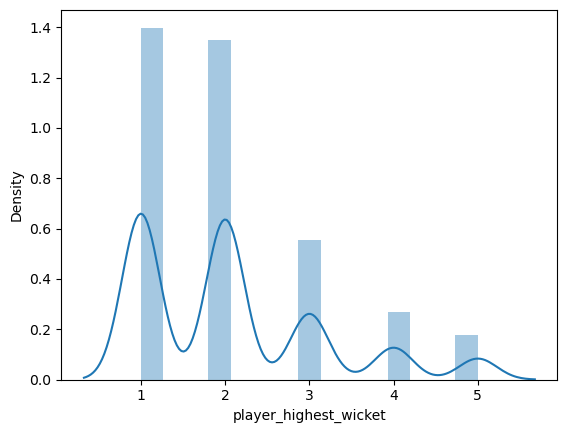

In [21]:
#  Univariate analysis for continuous variables
continuous_vars = ['Avg_team_Age', 'Audience_number', 'Max_run_scored_1over', 'Max_wicket_taken_1over', 'Extra_bowls_bowled', 'Min_run_given_1over', 'Min_run_scored_1over', 'Max_run_given_1over', 'extra_bowls_opponent', 'player_highest_run', 'Players_scored_zero', 'player_highest_wicket']
for var in continuous_vars:
    sns.distplot(df[var])
    plt.show()

<Axes: xlabel='Avg_team_Age', ylabel='Count'>

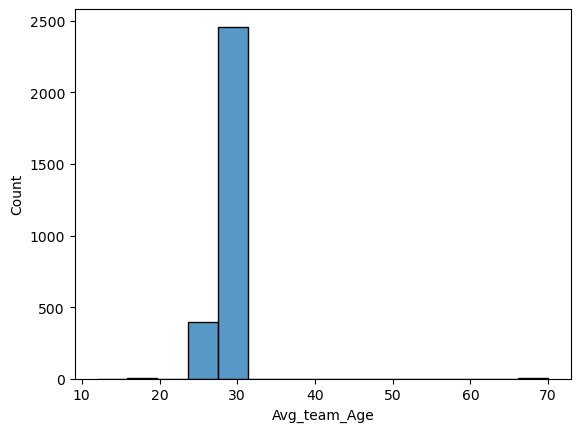

In [22]:
sns.histplot(data=df, x='Avg_team_Age', bins=15)

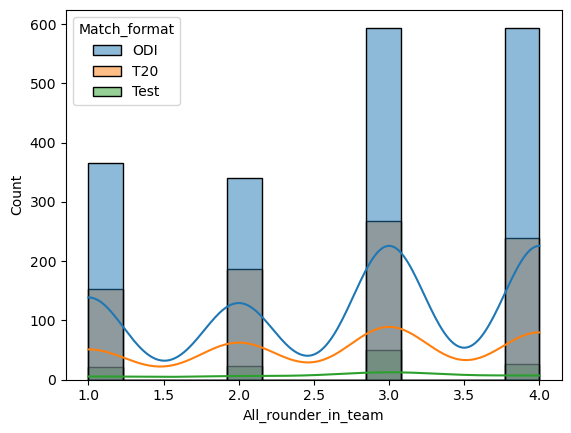

In [23]:
sns.histplot(data=df, x='All_rounder_in_team', hue='Match_format', kde=True);

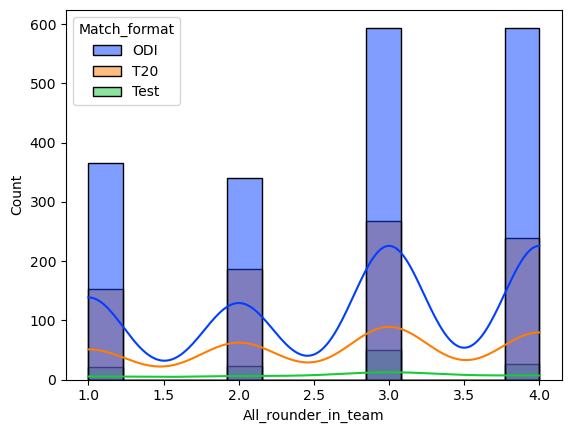

In [24]:
sns.histplot(data=df, x='All_rounder_in_team', hue='Match_format', kde=True, palette='bright');


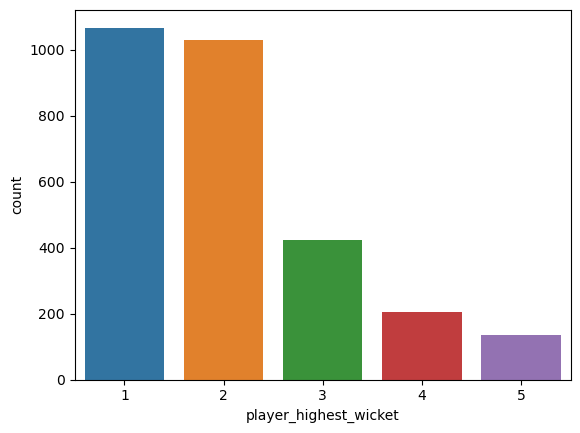

In [25]:
## Univariate Analysis Categorical variable

sns.countplot(x="player_highest_wicket", data=df);

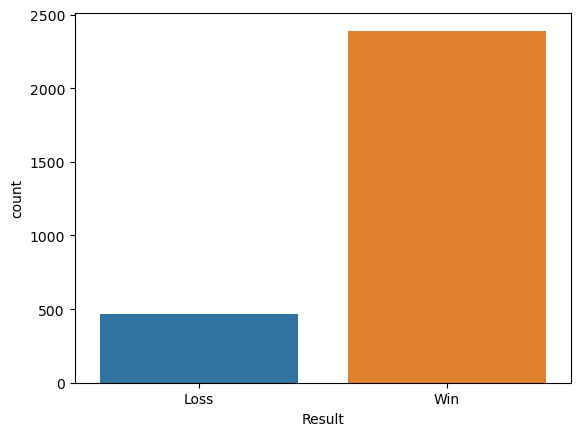

In [26]:
sns.countplot(x="Result", data=df);

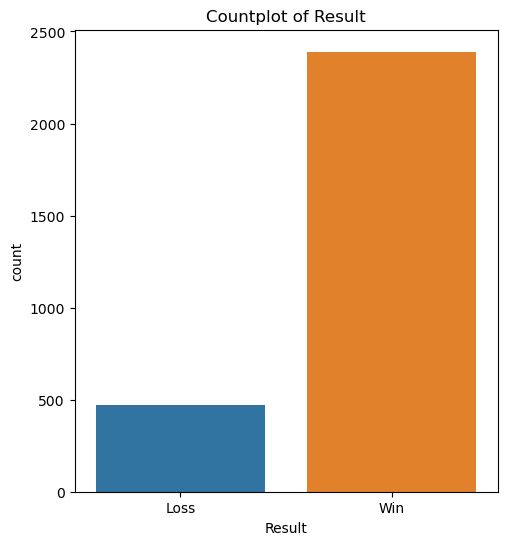

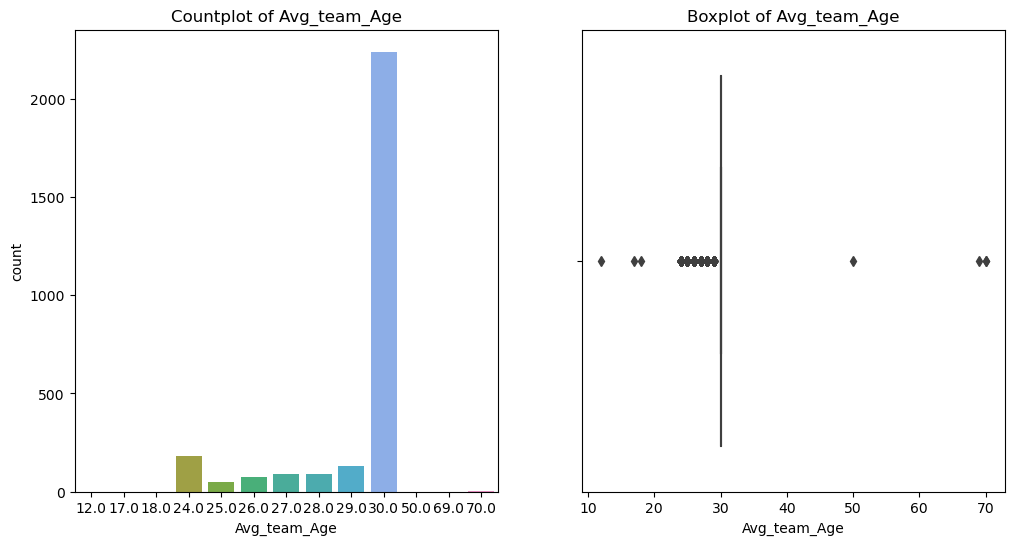

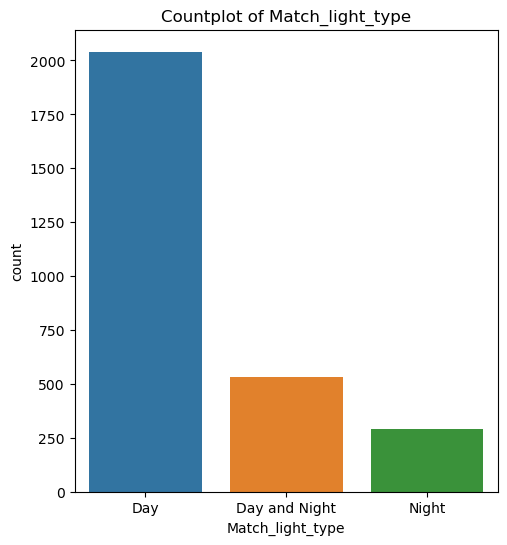

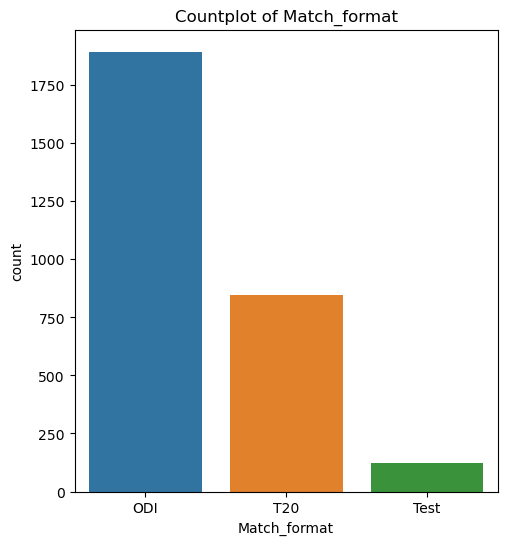

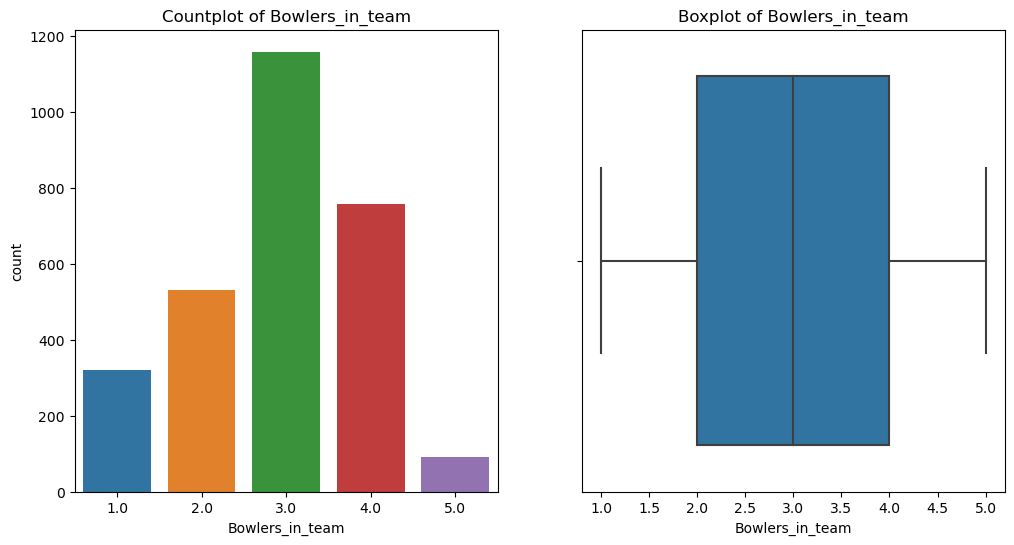

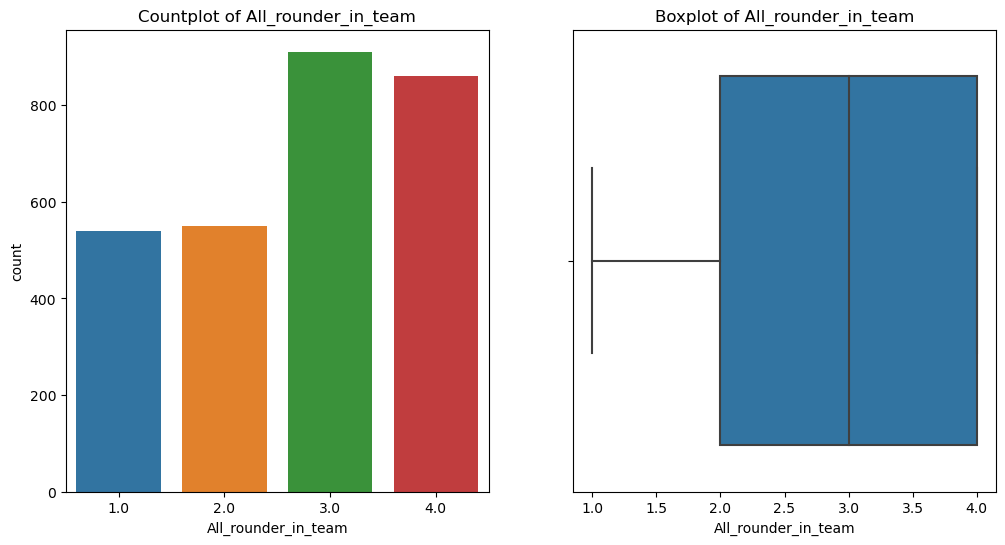

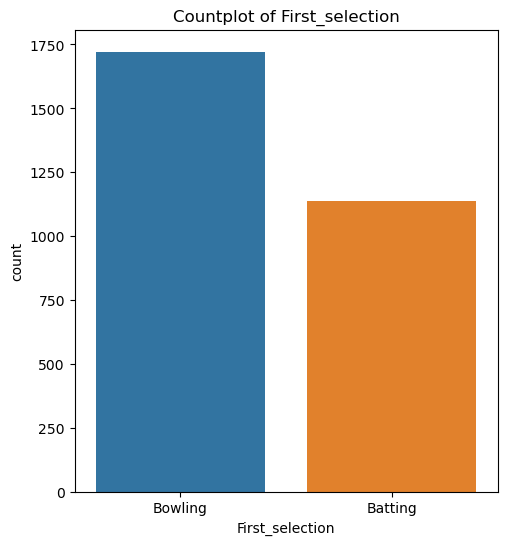

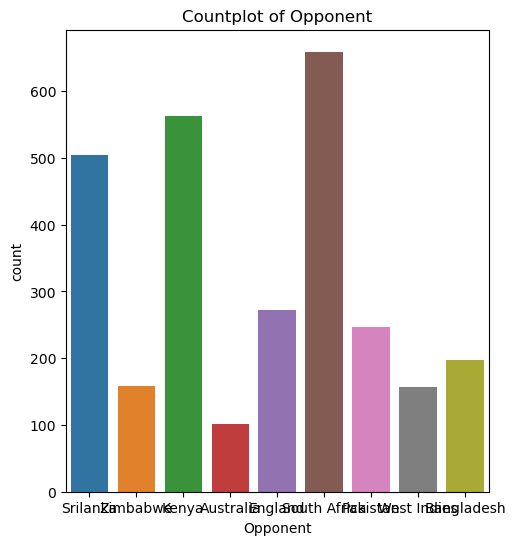

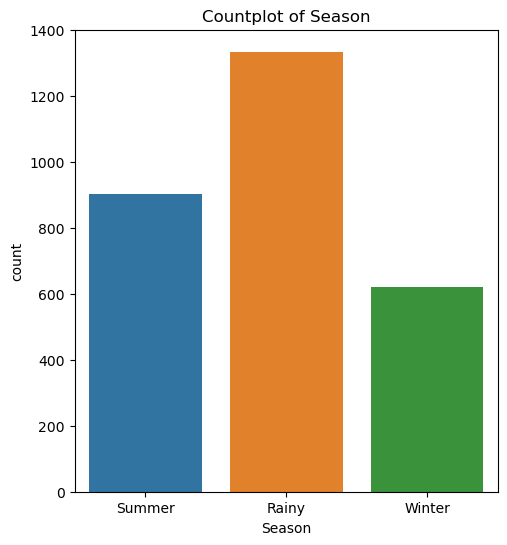

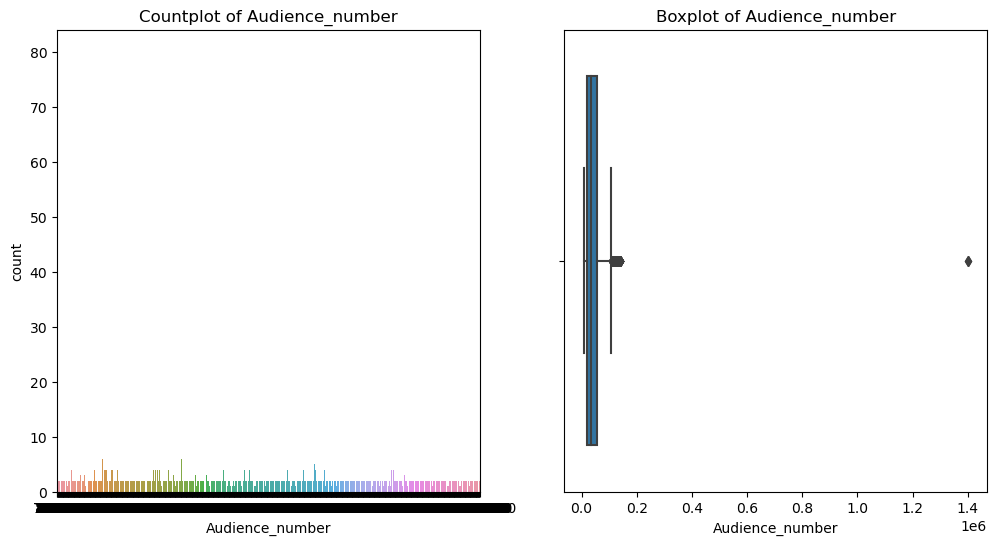

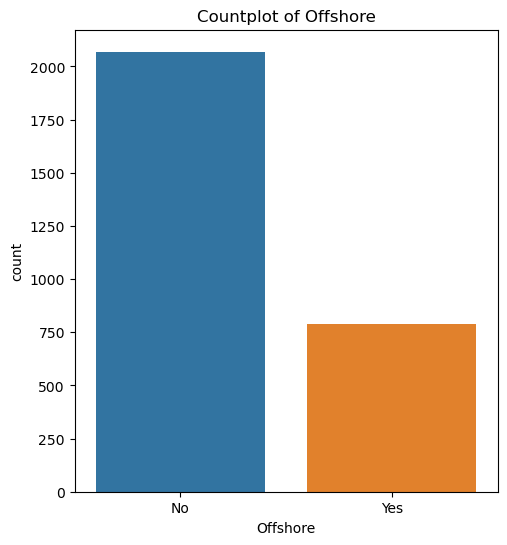

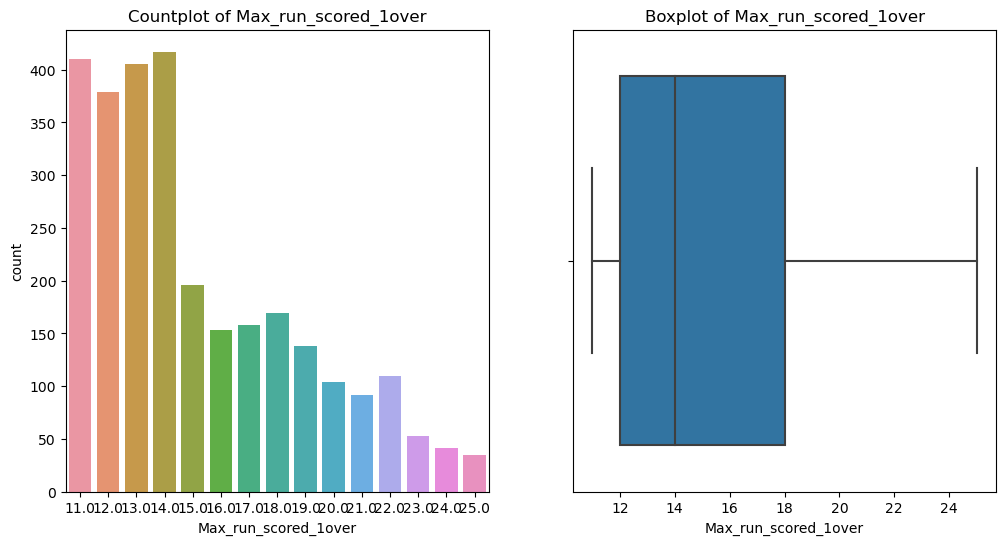

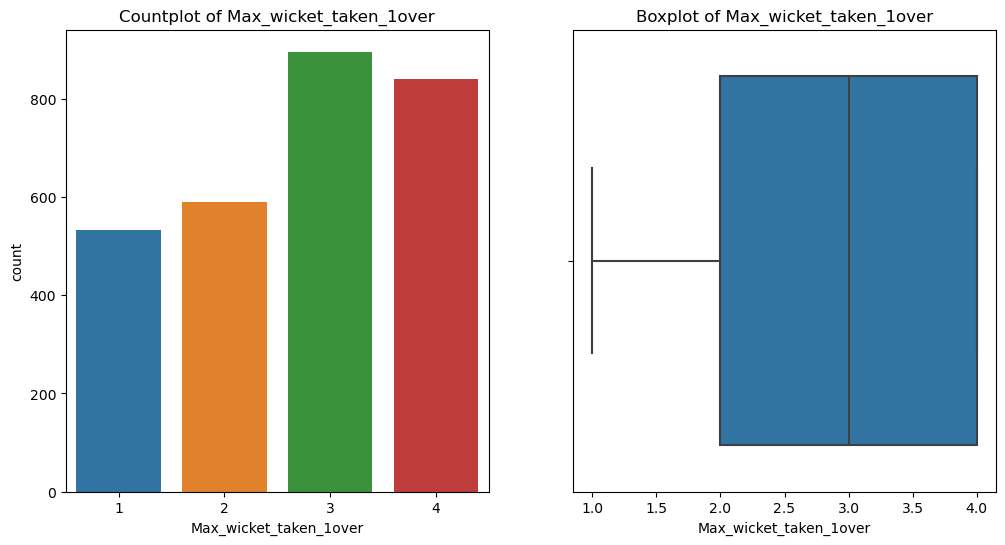

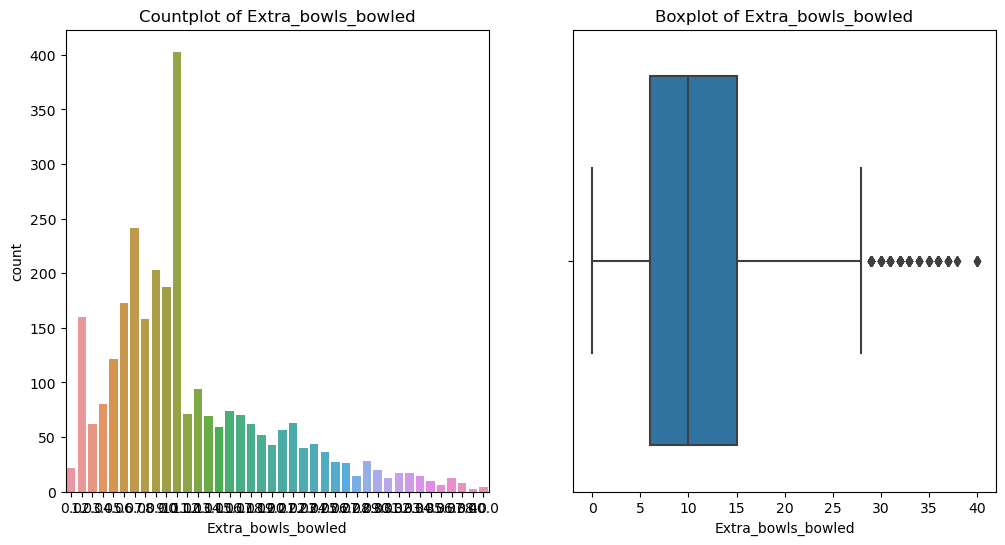

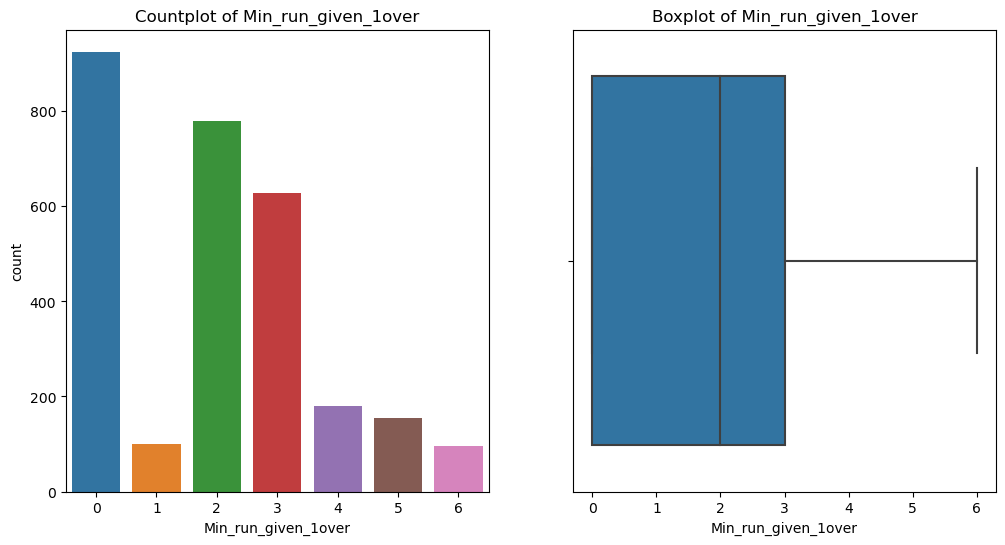

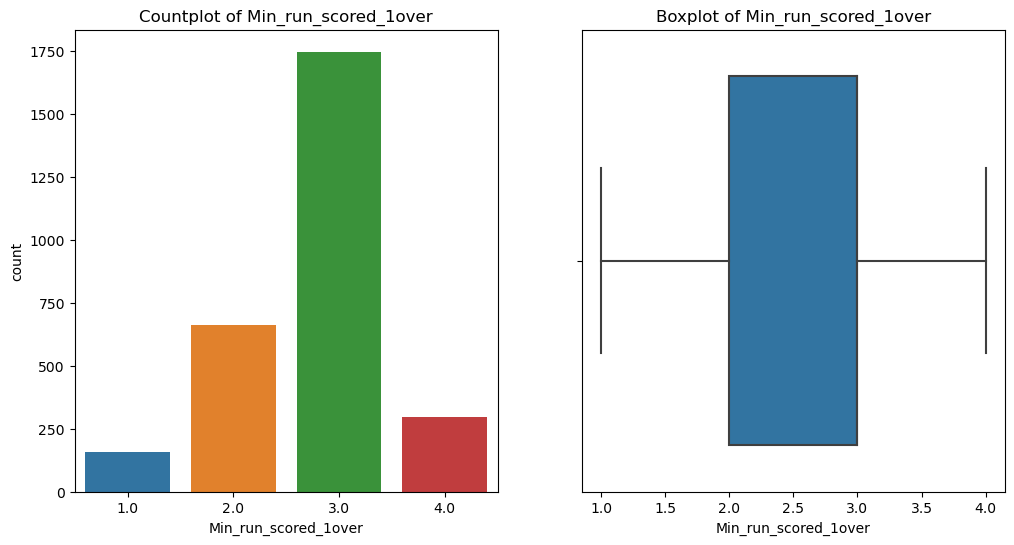

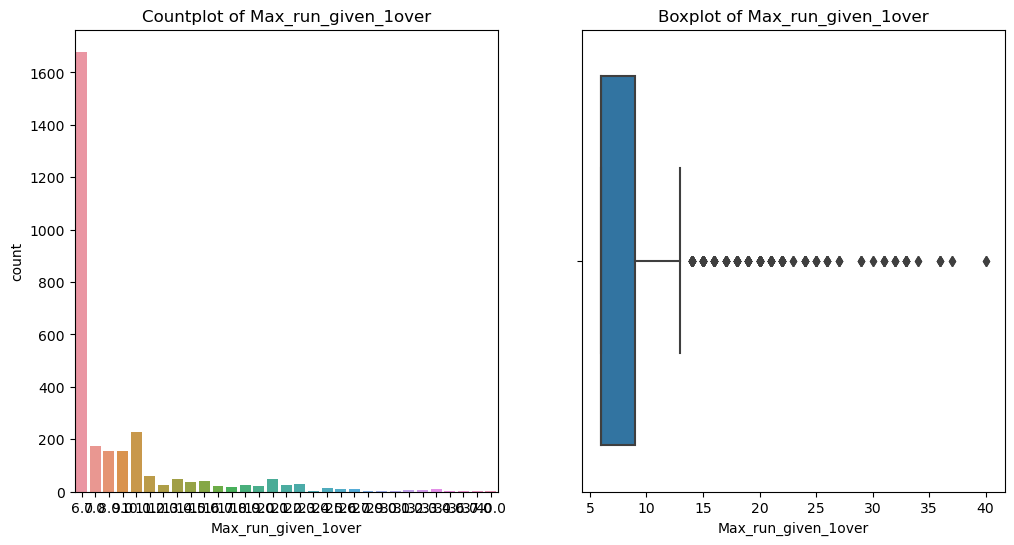

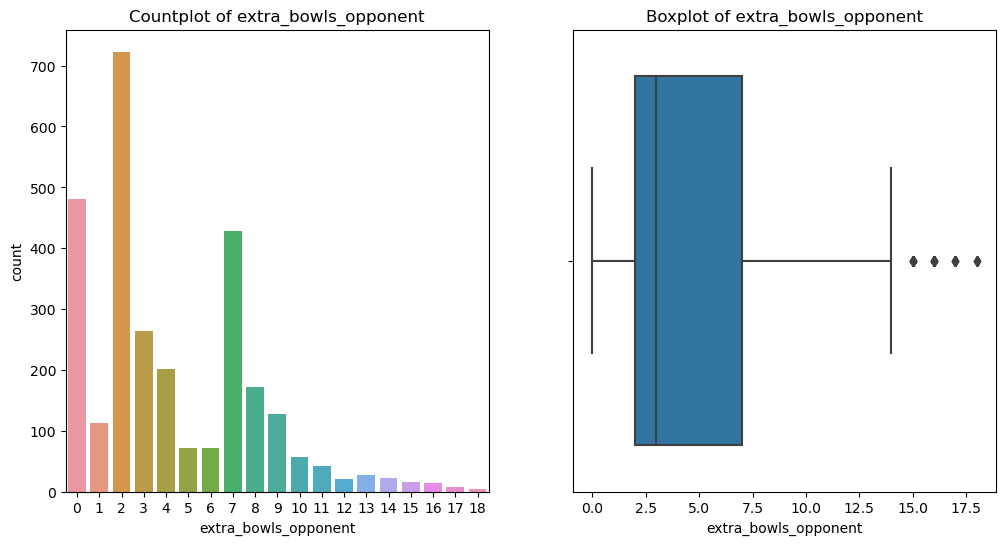

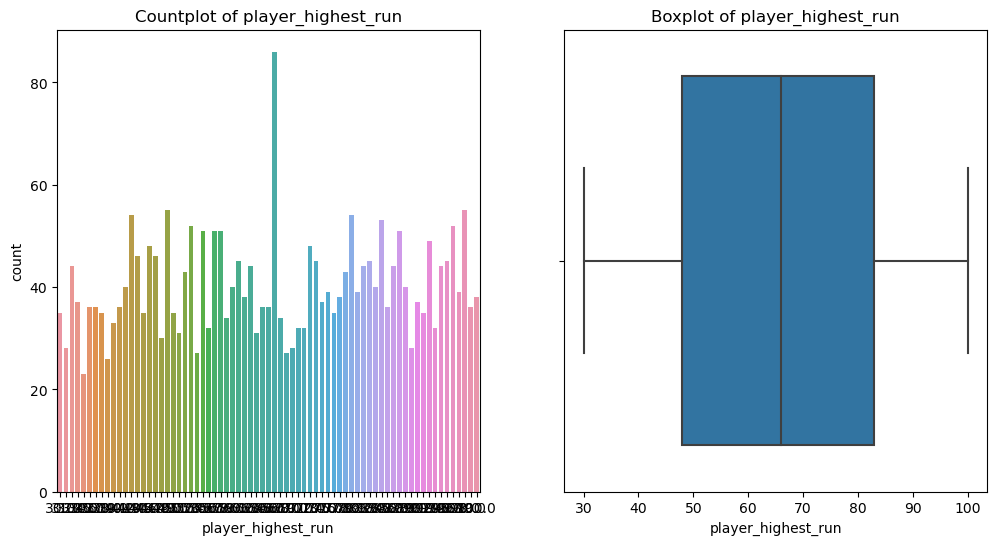

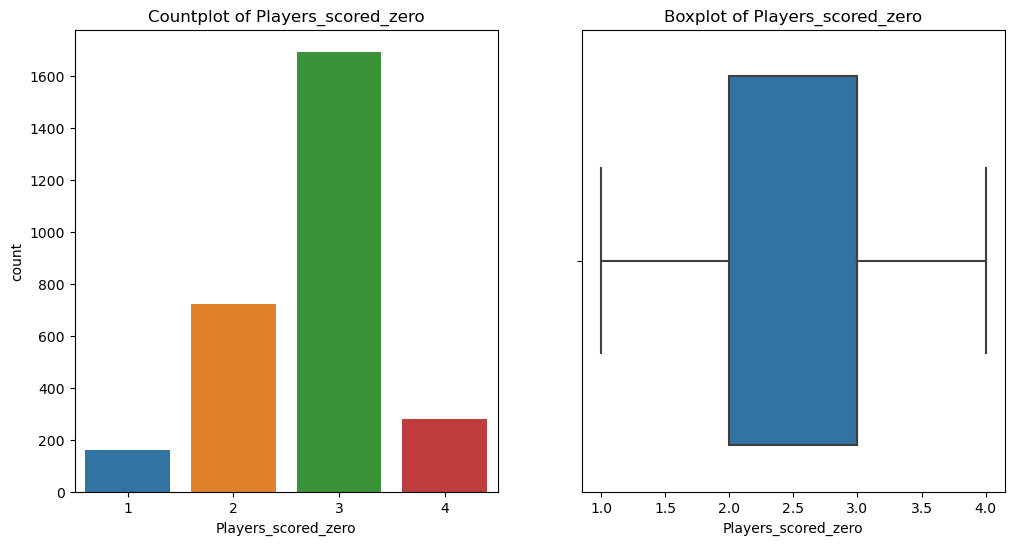

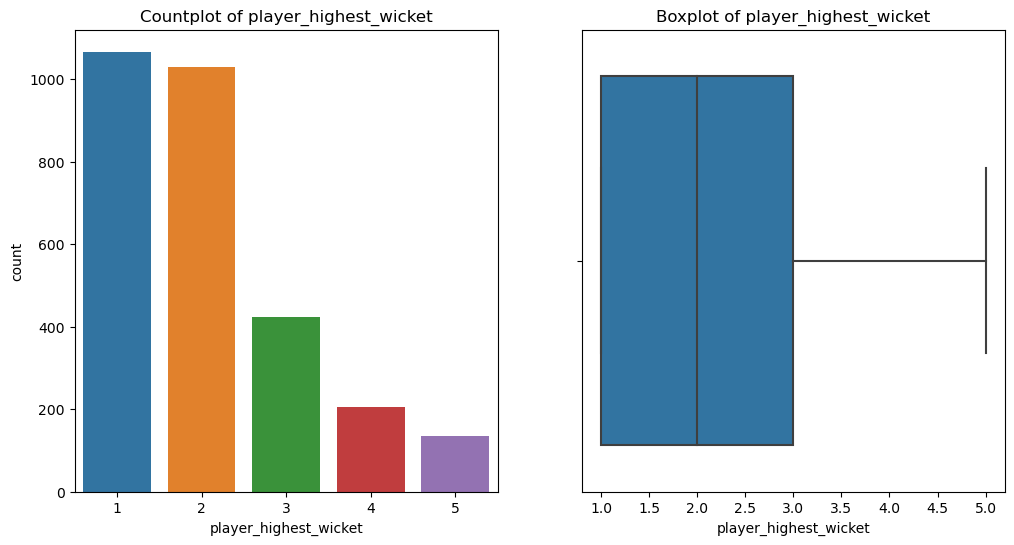

In [27]:
# plots for Univariate Analysis
variables = ['Result', 'Avg_team_Age', 'Match_light_type', 'Match_format', 'Bowlers_in_team', 
              'All_rounder_in_team', 'First_selection', 'Opponent', 'Season', 
             'Audience_number', 'Offshore', 'Max_run_scored_1over', 'Max_wicket_taken_1over', 
             'Extra_bowls_bowled', 'Min_run_given_1over', 'Min_run_scored_1over', 'Max_run_given_1over', 
             'extra_bowls_opponent', 'player_highest_run', 'Players_scored_zero', 'player_highest_wicket']

for var in variables:
    plt.figure(figsize=(12,6))
    
    # Countplot
    plt.subplot(1, 2, 1)
    sns.countplot(x=var, data=df)
    plt.title('Countplot of ' + var)
    
    # Boxplot
    if df[var].dtype in ['float64', 'int64']:  # Only make a boxplot for numeric columns
        plt.subplot(1, 2, 2)
        sns.boxplot(x=var, data=df)
        plt.title('Boxplot of ' + var)
    
    plt.show()

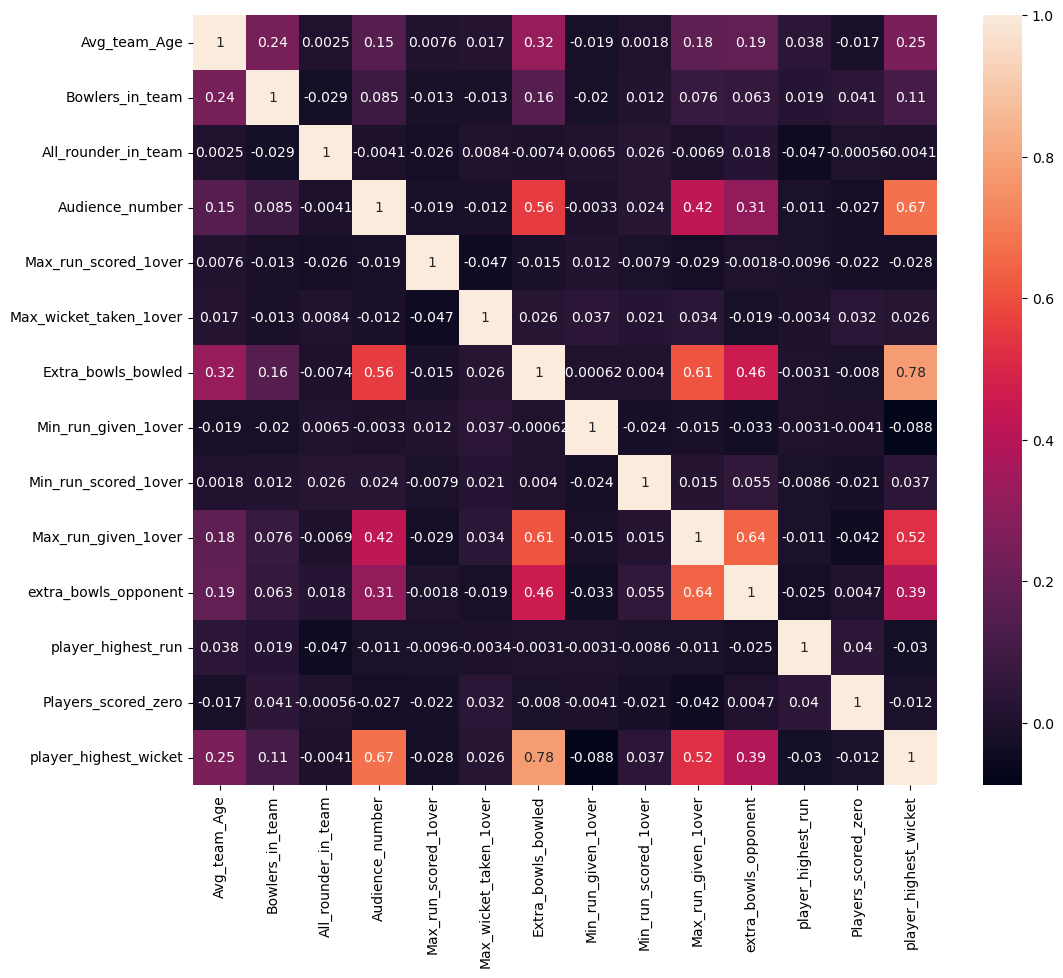

In [28]:
# Bivariate Analysis
correlation_matrix = df.corr()

# Set the size of the figure
plt.figure(figsize=(12, 10))

# Generate the heatmap
sns.heatmap(correlation_matrix, annot=True)

# Show the plot
plt.show()

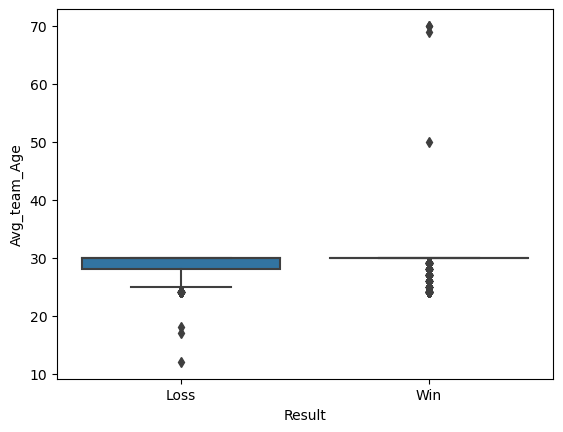

In [29]:
sns.boxplot(y='Avg_team_Age',x='Result', data=df);

<Axes: xlabel='Avg_team_Age', ylabel='Count'>

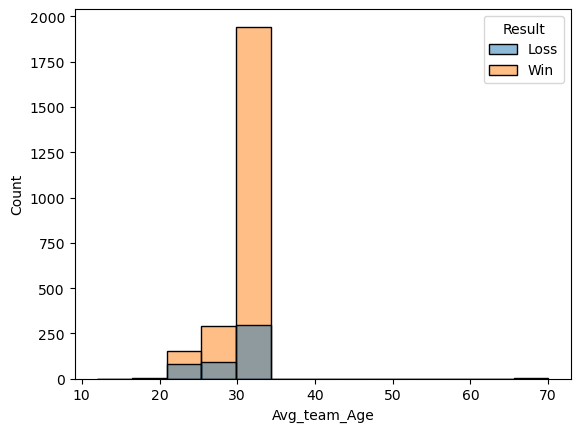

In [30]:
sns.histplot(data=df, x='Avg_team_Age', hue='Result')


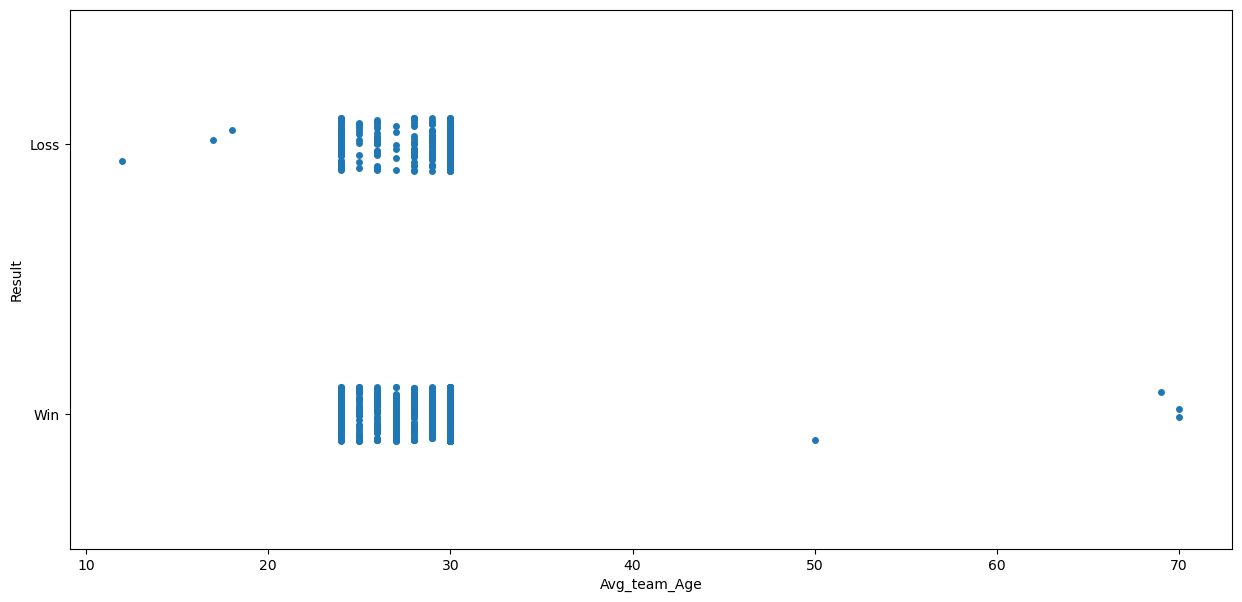

In [31]:
plt.figure(figsize=(15,7))
sns.stripplot(data=df, x='Avg_team_Age', y='Result');

In [32]:
## Unique value check
columns = ['Result', 'Avg_team_Age', 'Match_light_type', 'Match_format', 'Bowlers_in_team', 
            'All_rounder_in_team', 'First_selection', 'Opponent', 'Season', 
           'Audience_number', 'Offshore', 'Max_run_scored_1over', 'Max_wicket_taken_1over', 
           'Extra_bowls_bowled', 'Min_run_given_1over', 'Min_run_scored_1over', 'Max_run_given_1over', 
           'extra_bowls_opponent', 'player_highest_run', 'Players_scored_zero', 'player_highest_wicket']

for col in columns:
    unique_values = df[col].unique()
    print(f'Unique values for {col}: {unique_values}')

Unique values for Result: ['Loss' 'Win']
Unique values for Avg_team_Age: [18. 24. 30. 17. 12. 25. 26. 27. 28. 29. 70. 69. 50.]
Unique values for Match_light_type: ['Day' 'Day and Night' 'Night']
Unique values for Match_format: ['ODI' 'T20' 'Test']
Unique values for Bowlers_in_team: [3. 2. 1. 4. 5.]
Unique values for All_rounder_in_team: [3. 4. 2. 1.]
Unique values for First_selection: ['Bowling' 'Batting']
Unique values for Opponent: ['Srilanka' 'Zimbabwe' 'Kenya' 'Australia' 'England' 'South Africa'
 'Pakistan' 'West Indies' 'Bangladesh']
Unique values for Season: ['Summer' 'Rainy' 'Winter']
Unique values for Audience_number: [ 9940.  8400. 13146. ... 20937. 28756. 14007.]
Unique values for Offshore: ['No' 'Yes']
Unique values for Max_run_scored_1over: [13. 12. 14. 15. 16. 19. 21. 22. 25. 18. 11. 17. 24. 20. 23.]
Unique values for Max_wicket_taken_1over: [3 1 4 2]
Unique values for Extra_bowls_bowled: [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 17. 31. 13. 26. 24.
 22. 19. 23

<Axes: xlabel='Opponent', ylabel='count'>

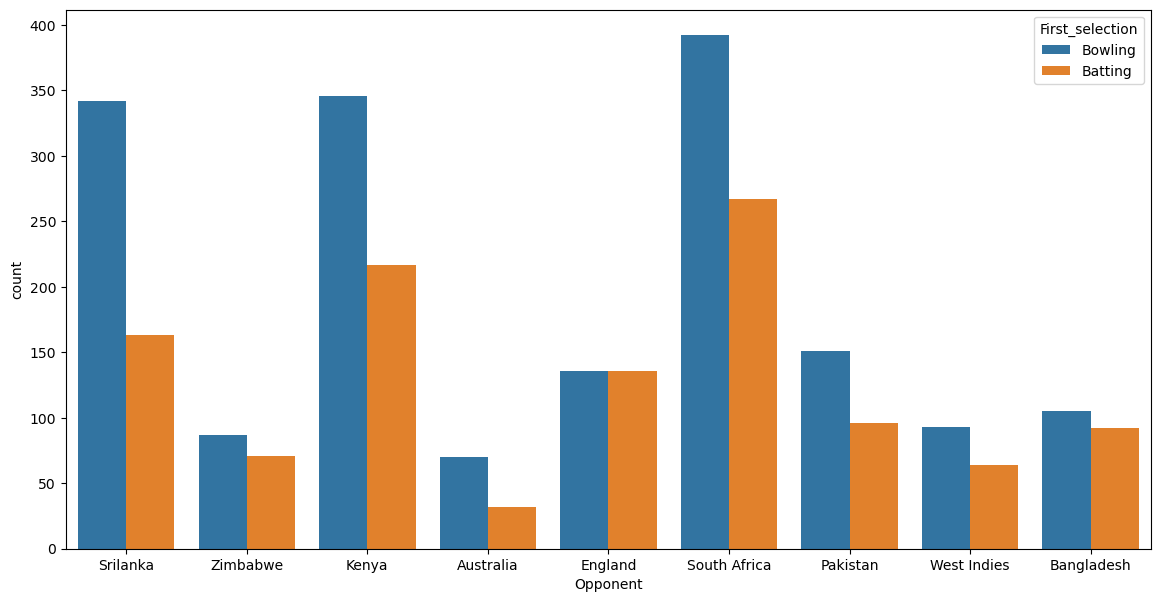

In [33]:
## Bivariate analysis

plt.figure(figsize=(14,7))
sns.countplot(data=df, x='Opponent', hue='First_selection')

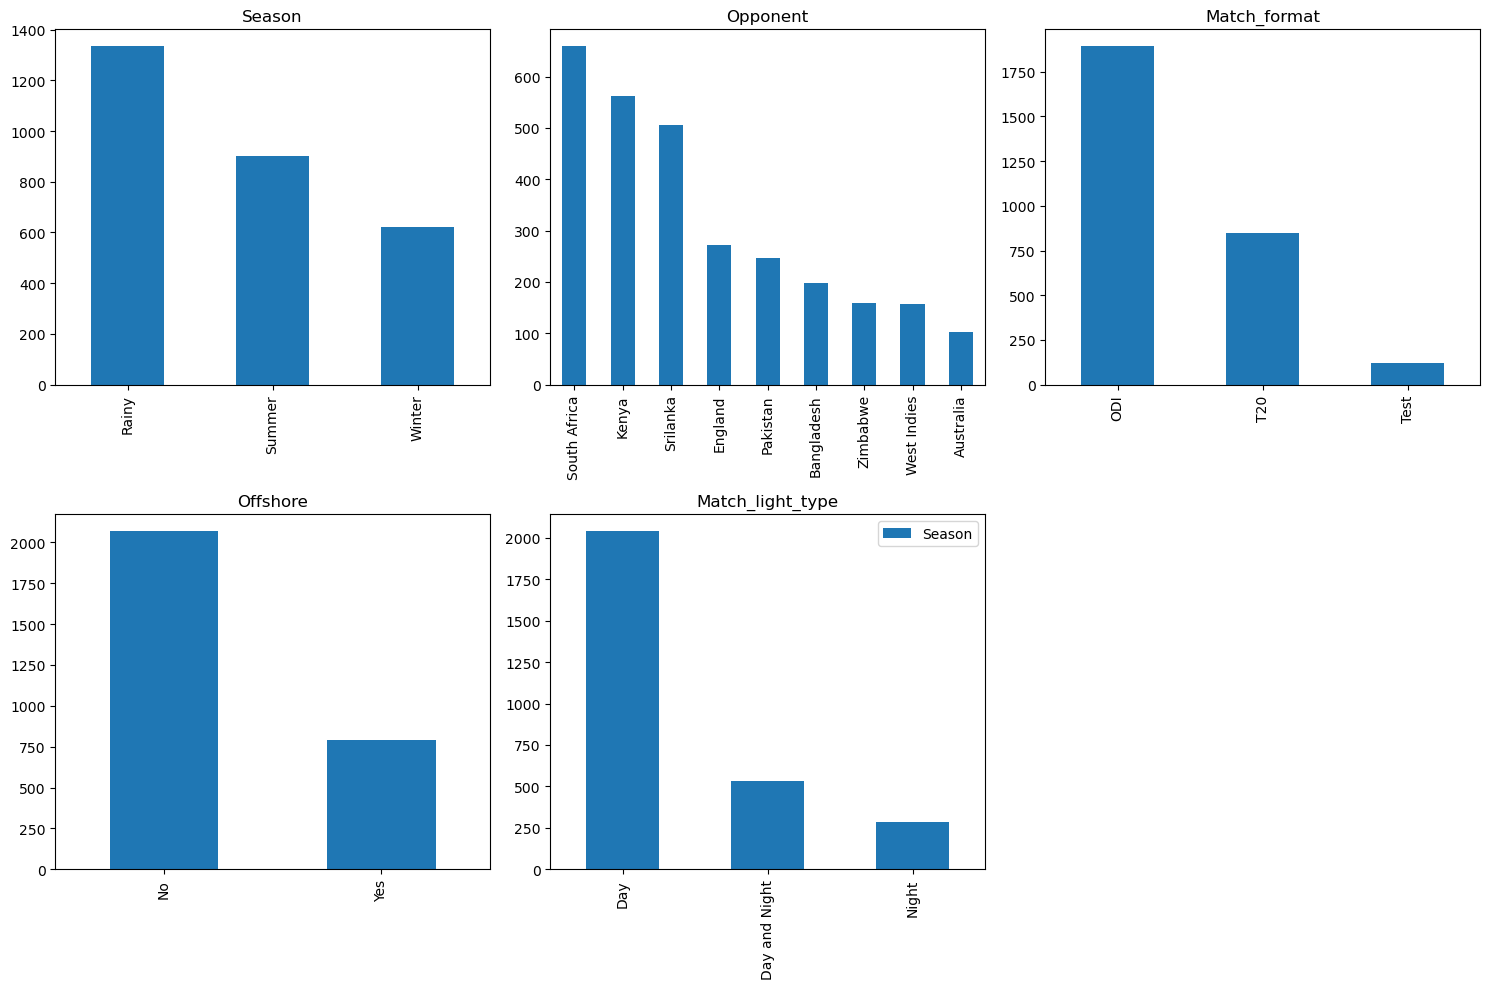

In [34]:

columns = ['Season', 'Opponent', 'Match_format', 'Offshore', 'Match_light_type']

plt.figure(figsize=(15,10))

for i, col in enumerate(columns):
    # Get value counts
    value_counts = df[col].value_counts()
    
    # Create subplot
    plt.subplot(2, 3, i+1)
    
    # Plot value counts
    value_counts.plot(kind='bar')
    
    # Set title
    plt.title(col)

# Show legend and plot
plt.legend(columns)
plt.tight_layout()
plt.show()

In [35]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Result,2860,2,Win,2390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Avg_team_Age,2860.0,NaN,NaN,NaN,29.260839,2.246867,12.0,30.0,30.0,30.0,70.0
Match_light_type,2860,3,Day,2041,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Match_format,2860,3,ODI,1893,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Bowlers_in_team,2860.0,NaN,NaN,NaN,2.917483,1.009664,1.0,2.0,3.0,4.0,5.0
All_rounder_in_team,2860.0,NaN,NaN,NaN,2.731469,1.084046,1.0,2.0,3.0,4.0,4.0
First_selection,2860,2,Bowling,1722,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Opponent,2860,9,South Africa,659,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Season,2860,3,Rainy,1335,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Audience_number,2860.0,NaN,NaN,NaN,45859.122028,48292.101525,7063.0,20550.25,34293.0,55916.0,1399930.0


In [36]:
sns.pairplot(df, height=5.5)  # Change the value as needed

# Show the plot
plt.show()

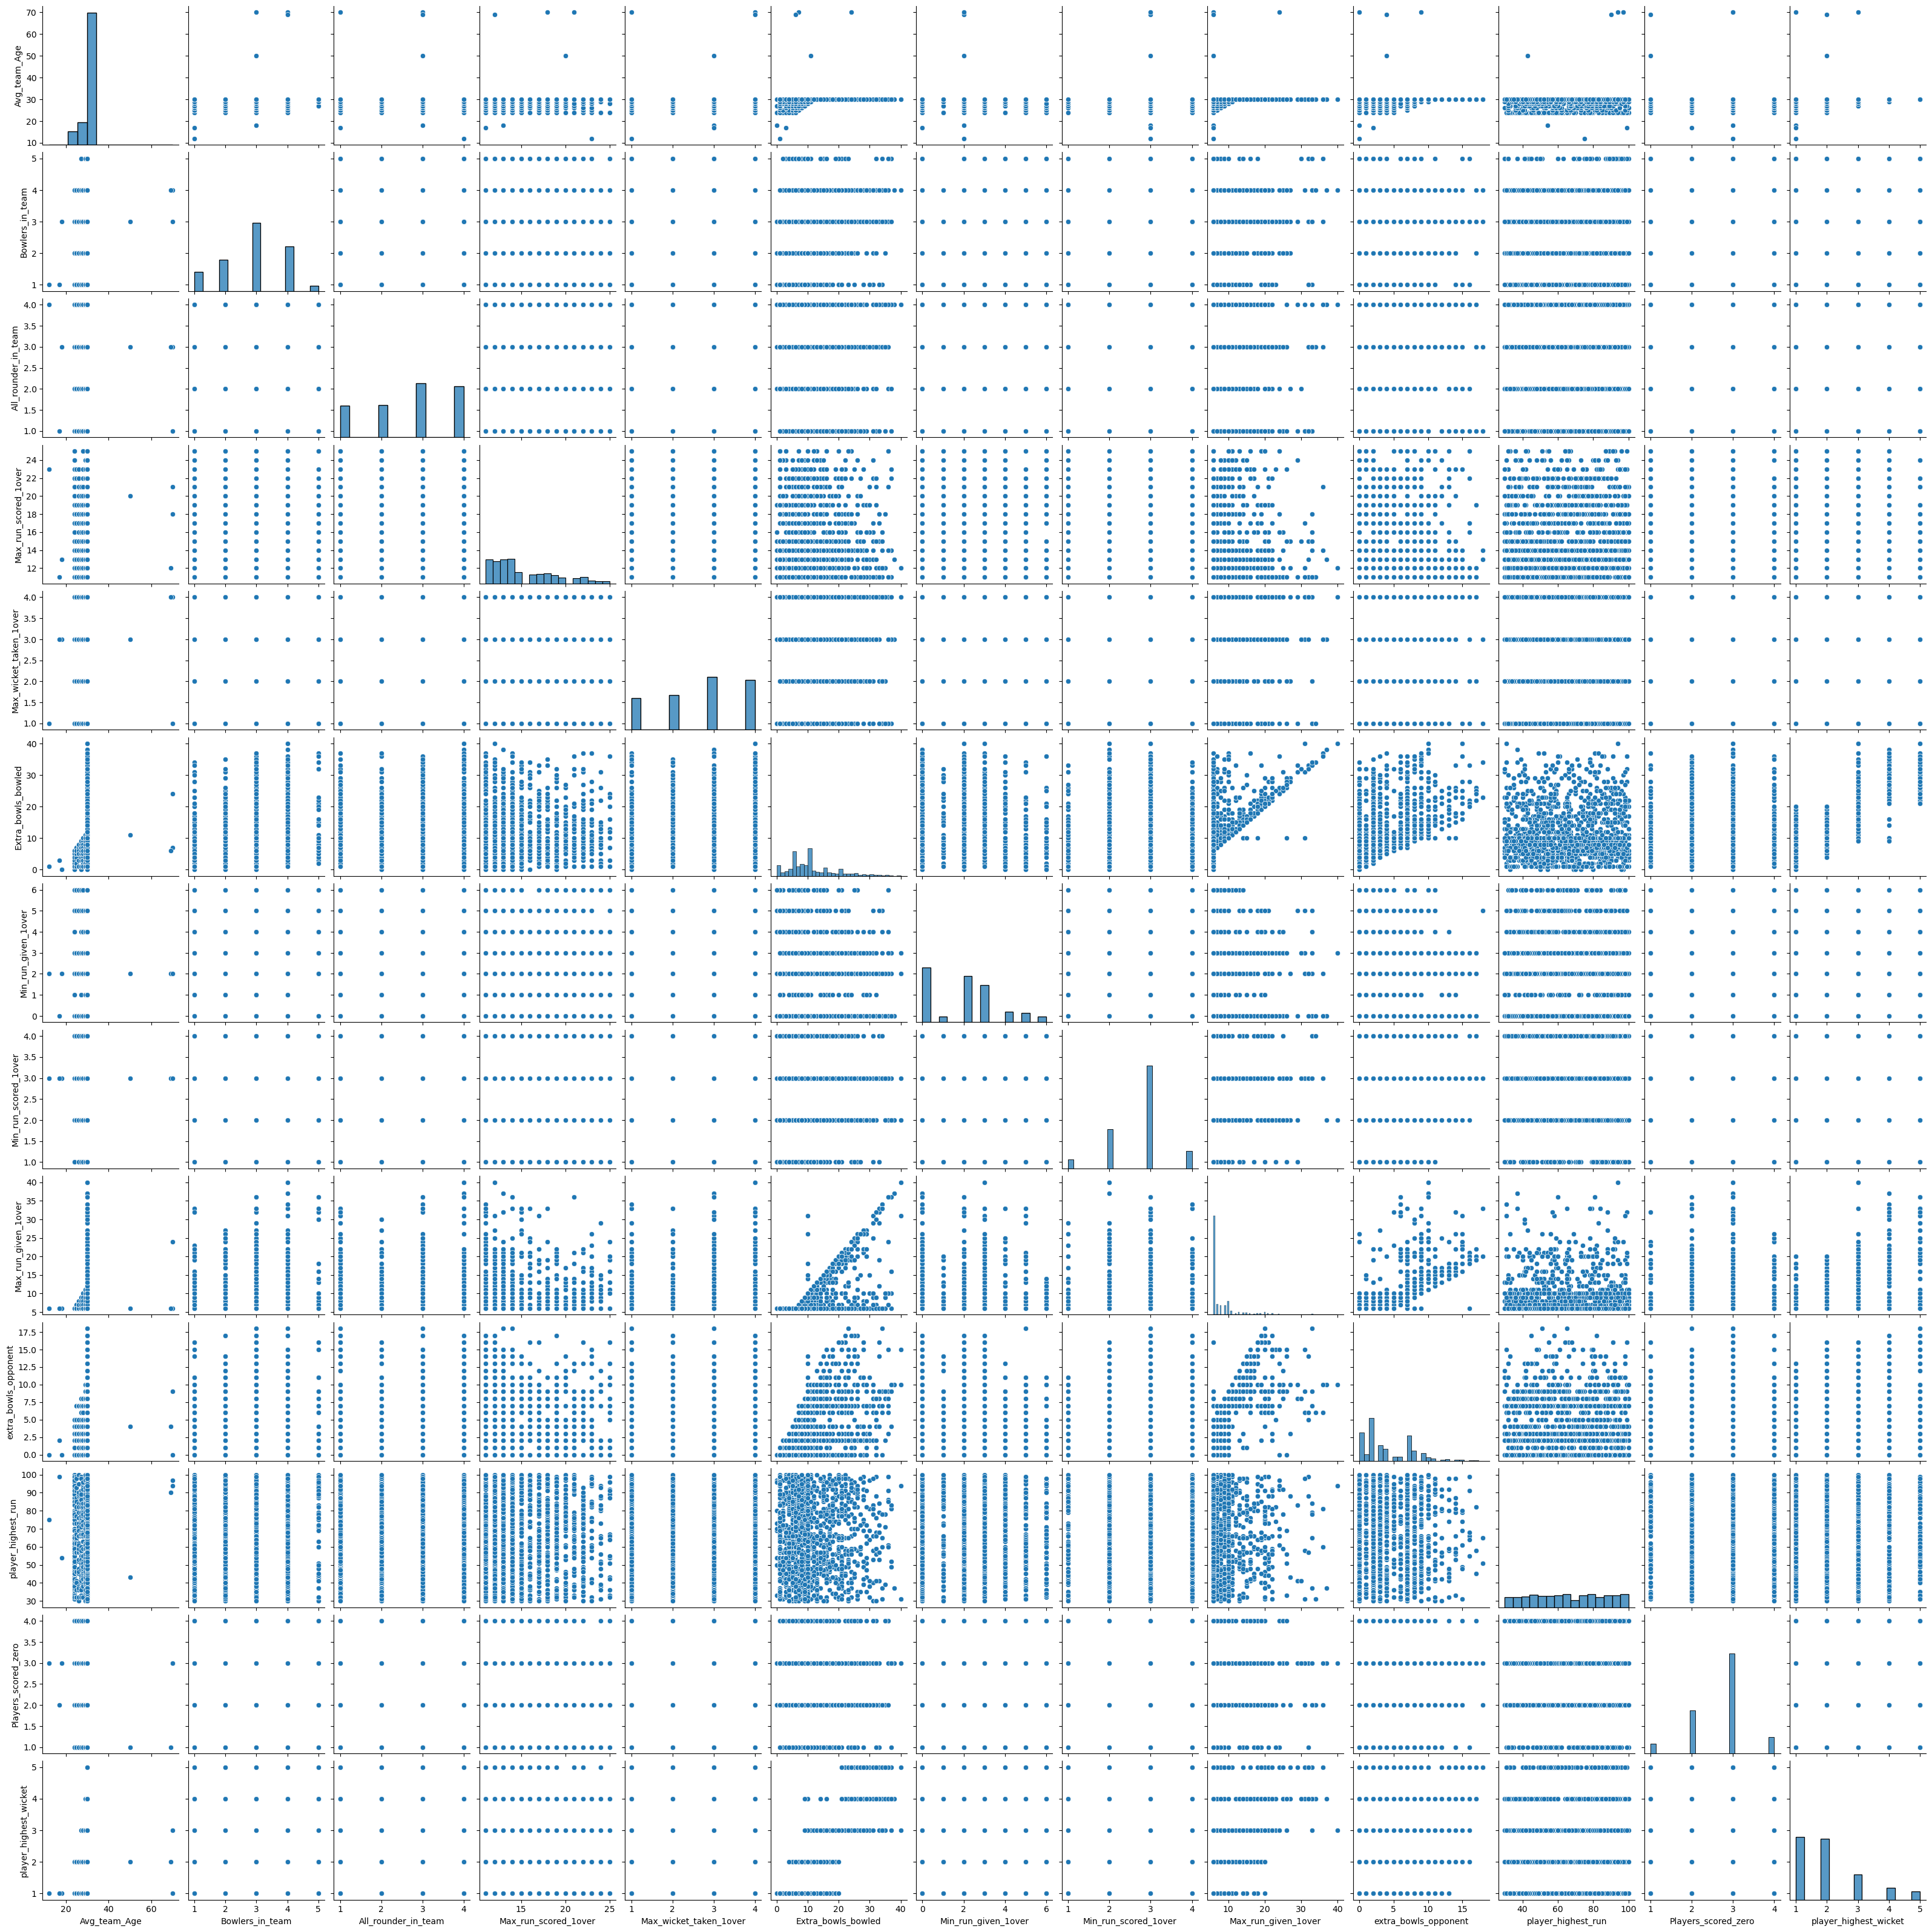

In [37]:
# Select a subset of the DataFrame
df_subset = df[['Result', 'Avg_team_Age', 'Match_light_type', 'Match_format', 'Bowlers_in_team', 'All_rounder_in_team', 'First_selection', 'Opponent', 'Max_run_scored_1over', 'Max_wicket_taken_1over', 'Extra_bowls_bowled', 'Min_run_given_1over', 'Min_run_scored_1over', 'Max_run_given_1over', 'extra_bowls_opponent', 'player_highest_run', 'Players_scored_zero', 'player_highest_wicket']]

# Construct the pairplot
sns.pairplot(df_subset)

# Show the plot
plt.show()

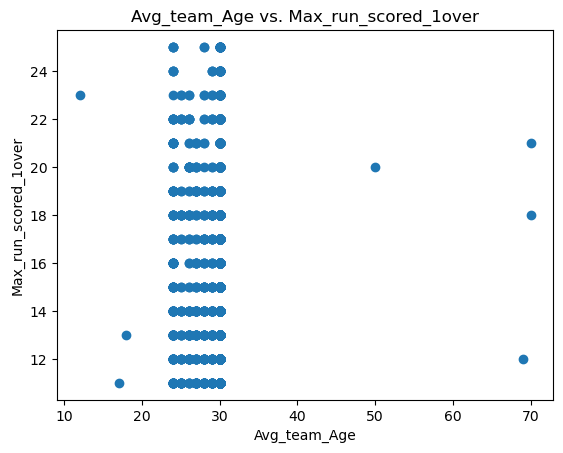

In [38]:
# Scatter plot
plt.scatter(df['Avg_team_Age'], df['Max_run_scored_1over'])
plt.xlabel('Avg_team_Age')
plt.ylabel('Max_run_scored_1over')
plt.title('Avg_team_Age vs. Max_run_scored_1over')
plt.show()

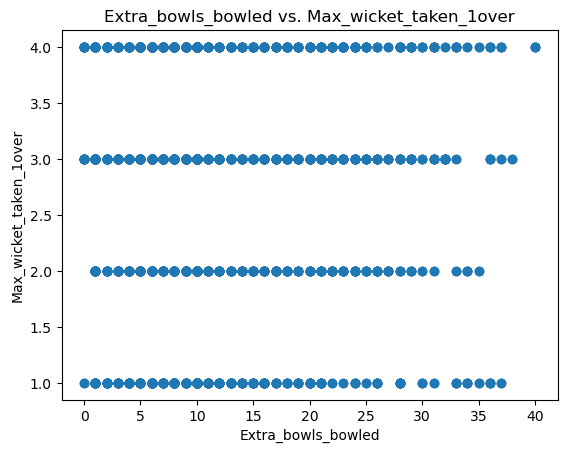

In [39]:
# Scatter plot
plt.scatter(df['Extra_bowls_bowled'], df['Max_wicket_taken_1over'])
plt.xlabel('Extra_bowls_bowled')
plt.ylabel('Max_wicket_taken_1over')
plt.title('Extra_bowls_bowled vs. Max_wicket_taken_1over')
plt.show()

In [40]:
## Bivariate analysis

<Axes: xlabel='Result', ylabel='count'>

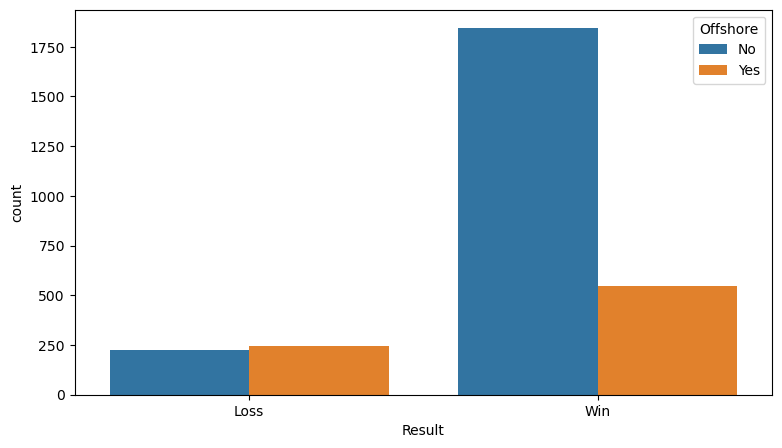

In [41]:
plt.figure(figsize=(9,5))
sns.countplot(data=df, x='Result', hue='Offshore')

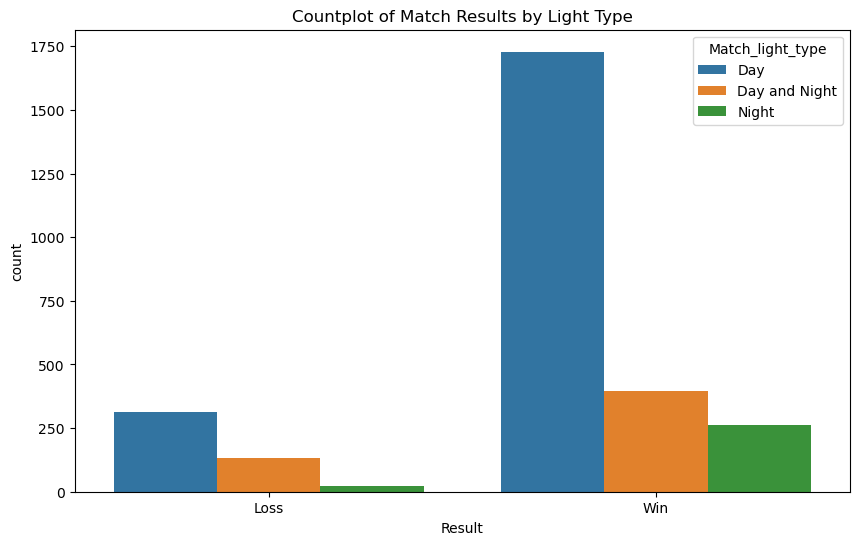

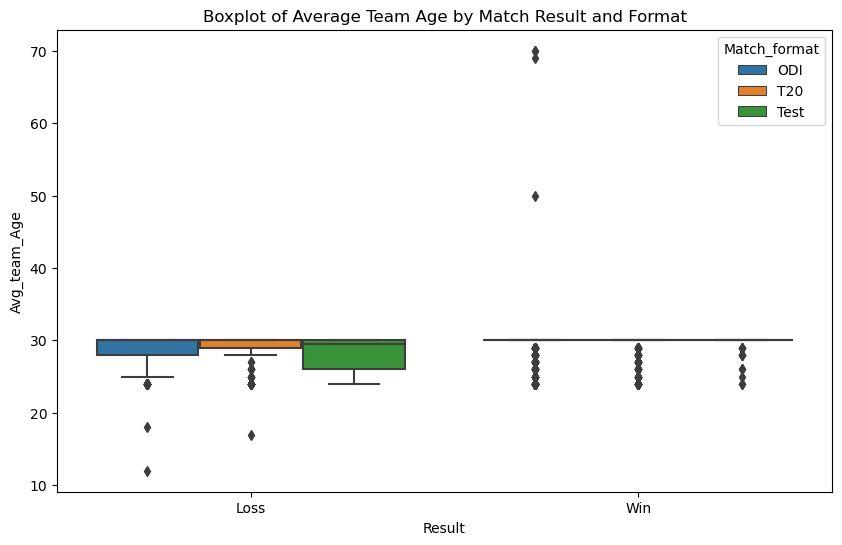

In [42]:

plt.figure(figsize=(10,6))
sns.countplot(x='Result', hue='Match_light_type', data=df)
plt.title('Countplot of Match Results by Light Type')
plt.show()

# Create a boxplot
plt.figure(figsize=(10,6))
sns.boxplot(x='Result', y='Avg_team_Age', hue='Match_format', data=df)
plt.title('Boxplot of Average Team Age by Match Result and Format')
plt.show()

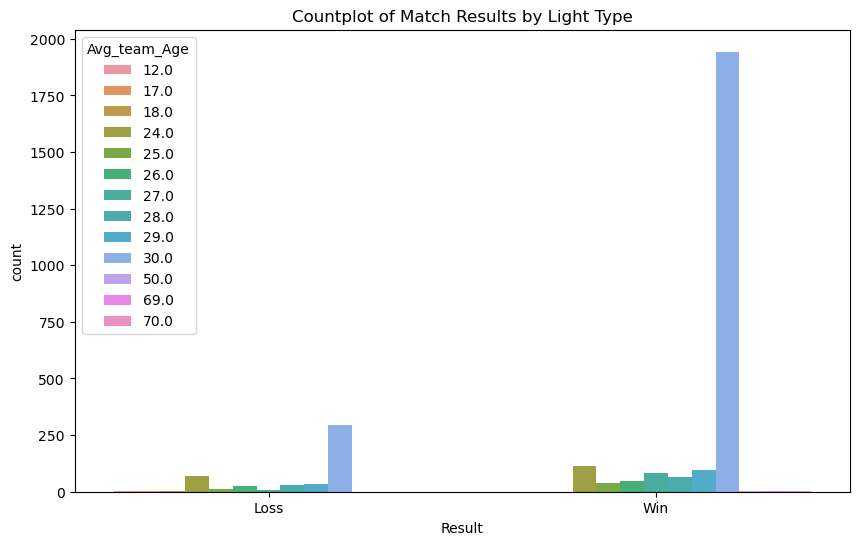

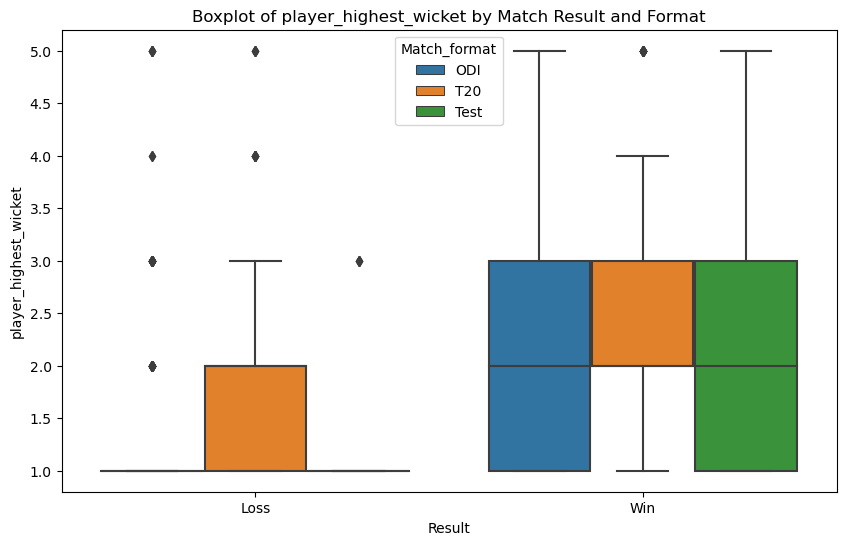

In [43]:
# Create a countplot
plt.figure(figsize=(10,6))
sns.countplot(x='Result', hue='Avg_team_Age', data=df)
plt.title('Countplot of Match Results by Light Type')
plt.show()

# Create a boxplot
plt.figure(figsize=(10,6))
sns.boxplot(x='Result', y='player_highest_wicket', hue='Match_format', data=df)
plt.title('Boxplot of player_highest_wicket by Match Result and Format')
plt.show()

In [44]:
df['Match_light_type']=pd.Categorical(df['Match_light_type']).codes
df['Match_format']=pd.Categorical(df['Match_format']).codes
df['Opponent']=pd.Categorical(df['Opponent']).codes

In [45]:
## preparing data for futher statistical analysis
## to convert categorical data into a numerical format

df['Result']=pd.Categorical(df['Result']).codes
df['First_selection']=pd.Categorical(df['First_selection']).codes

df['Season']=pd.Categorical(df['Season']).codes
df['Offshore']=pd.Categorical(df['Offshore']).codes


In [46]:
df['Offshore'].value_counts()

0    2069
1     791
Name: Offshore, dtype: int64

In [47]:
df.head()

,Result,Avg_team_Age,Match_light_type,Match_format,Bowlers_in_team,All_rounder_in_team,First_selection,Opponent,Season,Audience_number,...,Max_run_scored_1over,Max_wicket_taken_1over,Extra_bowls_bowled,Min_run_given_1over,Min_run_scored_1over,Max_run_given_1over,extra_bowls_opponent,player_highest_run,Players_scored_zero,player_highest_wicket
0,0,18.0,0,0,3.0,3.0,1,6,1,9940.0,...,13.0,3,0.0,2,3.0,6.0,0,54.0,3,1
1,1,24.0,0,1,3.0,4.0,0,8,1,8400.0,...,12.0,1,0.0,0,3.0,6.0,0,69.0,2,1
2,0,24.0,1,1,3.0,2.0,1,8,0,13146.0,...,14.0,4,0.0,0,3.0,6.0,0,69.0,3,1
3,1,24.0,0,0,2.0,2.0,1,3,1,7357.0,...,15.0,4,0.0,2,3.0,6.0,0,73.0,3,1
4,0,24.0,2,0,1.0,3.0,1,6,1,13328.0,...,12.0,4,0.0,0,3.0,6.0,0,80.0,3,1


In [81]:
df['Match_format'].value_counts()

0    1893
1     846
2     121
Name: Match_format, dtype: int64

In [49]:
## NOTES 2 Model building and interpretation

In [50]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 2860 entries, 0 to 2929
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Result                  2860 non-null   int8   
 1   Avg_team_Age            2860 non-null   float64
 2   Match_light_type        2860 non-null   int8   
 3   Match_format            2860 non-null   int8   
 4   Bowlers_in_team         2860 non-null   float64
 5   All_rounder_in_team     2860 non-null   float64
 6   First_selection         2860 non-null   int8   
 7   Opponent                2860 non-null   int8   
 8   Season                  2860 non-null   int8   
 9   Audience_number         2860 non-null   float64
 10  Offshore                2860 non-null   int8   
 11  Max_run_scored_1over    2860 non-null   float64
 12  Max_wicket_taken_1over  2860 non-null   int64  
 13  Extra_bowls_bowled      2860 non-null   float64
 14  Min_run_given_1over     2860 non-null   

In [51]:
x = df.drop(["Result"],axis =1)
y = df["Result"]

In [52]:
x

,Avg_team_Age,Match_light_type,Match_format,Bowlers_in_team,All_rounder_in_team,First_selection,Opponent,Season,Audience_number,Offshore,Max_run_scored_1over,Max_wicket_taken_1over,Extra_bowls_bowled,Min_run_given_1over,Min_run_scored_1over,Max_run_given_1over,extra_bowls_opponent,player_highest_run,Players_scored_zero,player_highest_wicket
0,18.0,0,0,3.0,3.0,1,6,1,9940.0,0,13.0,3,0.0,2,3.0,6.0,0,54.0,3,1
1,24.0,0,1,3.0,4.0,0,8,1,8400.0,0,12.0,1,0.0,0,3.0,6.0,0,69.0,2,1
2,24.0,1,1,3.0,2.0,1,8,0,13146.0,1,14.0,4,0.0,0,3.0,6.0,0,69.0,3,1
3,24.0,0,0,2.0,2.0,1,3,1,7357.0,0,15.0,4,0.0,2,3.0,6.0,0,73.0,3,1
4,24.0,2,0,1.0,3.0,1,6,1,13328.0,0,12.0,4,0.0,0,3.0,6.0,0,80.0,3,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,30.0,0,1,3.0,4.0,0,5,1,33950.0,0,15.0,3,8.0,0,3.0,6.0,3,50.0,3,2
2926,30.0,0,0,4.0,3.0,1,3,1,19663.0,0,14.0,4,8.0,2,3.0,6.0,2,52.0,2,1
2927,30.0,1,0,4.0,3.0,1,4,0,39823.0,1,14.0,4,10.0,2,4.0,10.0,2,80.0,3,2
2928,30.0,0,0,4.0,3.0,0,3,0,14007.0,0,14.0,2,20.0,2,3.0,6.0,3,98.0,3,1


In [53]:
y.shape

(2860,)

In [54]:
x.shape

(2860, 20)

In [55]:
# Split the data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42)


In [56]:
#  the shape of the training set
print(f"x_train shape: {x_train.shape}")
print(f"y_train shape: {y_train.shape}")

#  the shape of the testing set
print(f"x_test shape: {x_test.shape}")
print(f"y_test shape: {y_test.shape}")

# set details
print(f"\nDetails:")
print(f"Number of samples in training set: {x_train.shape[0]}")
print(f"Number of features in training set: {x_train.shape[1]}")
print(f"Number of samples in testing set: {x_test.shape[0]}")
print(f"Number of features in testing set: {x_test.shape[1]}")

x_train shape: (2002, 20)
y_train shape: (2002,)
x_test shape: (858, 20)
y_test shape: (858,)

Details:
Number of samples in training set: 2002
Number of features in training set: 20
Number of samples in testing set: 858
Number of features in testing set: 20


In [57]:
from sklearn.metrics import classification_report

In [58]:
# Create an instance of LogisticRegression
logistic_model = LogisticRegression()

# Assuming x_train and y_train are already defined and contain the training data and labels
# Train the logistic model using the training data
logistic_model.fit(x_train, y_train)


LogisticRegression()

The accuracy of the logistic regression model on the training data is: 0.8396603396603397
The accuracy of the logistic regression model on the test data is: 0.8414918414918415


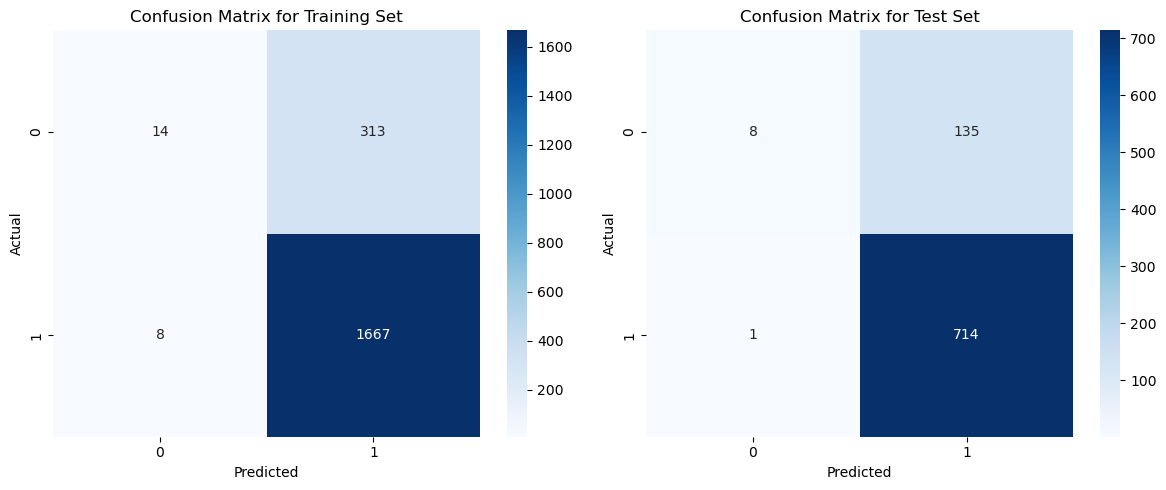

In [59]:
# Generate predictions for both train and test sets
y_predict_train = logistic_model.predict(x_train)
y_predict_test = logistic_model.predict(x_test)

# Calculate the accuracy of the model on both train and test sets
accuracy_train = accuracy_score(y_train, y_predict_train)
accuracy_test = accuracy_score(y_test, y_predict_test)

# Print the accuracy for both train and test sets
print(f"The accuracy of the logistic regression model on the training data is: {accuracy_train}")
print(f"The accuracy of the logistic regression model on the test data is: {accuracy_test}")

# Create confusion matrices for both train and test sets
confusion_matrix_train = confusion_matrix(y_train, y_predict_train)
confusion_matrix_test = confusion_matrix(y_test, y_predict_test)

# Create heatmaps for the confusion matrices
plt.figure(figsize=(12, 5))

# Heatmap for the training set
plt.subplot(1, 2, 1)
sns.heatmap(confusion_matrix_train, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix for Training Set')
plt.xlabel('Predicted')
plt.ylabel('Actual')

# Heatmap for the test set
plt.subplot(1, 2, 2)
sns.heatmap(confusion_matrix_test, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix for Test Set')
plt.xlabel('Predicted')
plt.ylabel('Actual')

# Show the heatmaps
plt.tight_layout()
plt.show()

In [60]:
# Print classification reports for the training set
print("Classification Report for Training Set:")
print(classification_report(y_train, y_predict_train))

# Print classification reports for the test set
print("Classification Report for Test Set:")
print(classification_report(y_test, y_predict_test))

Classification Report for Training Set:
              precision    recall  f1-score   support

           0       0.64      0.04      0.08       327
           1       0.84      1.00      0.91      1675

    accuracy                           0.84      2002
   macro avg       0.74      0.52      0.50      2002
weighted avg       0.81      0.84      0.78      2002

Classification Report for Test Set:
              precision    recall  f1-score   support

           0       0.89      0.06      0.11       143
           1       0.84      1.00      0.91       715

    accuracy                           0.84       858
   macro avg       0.86      0.53      0.51       858
weighted avg       0.85      0.84      0.78       858



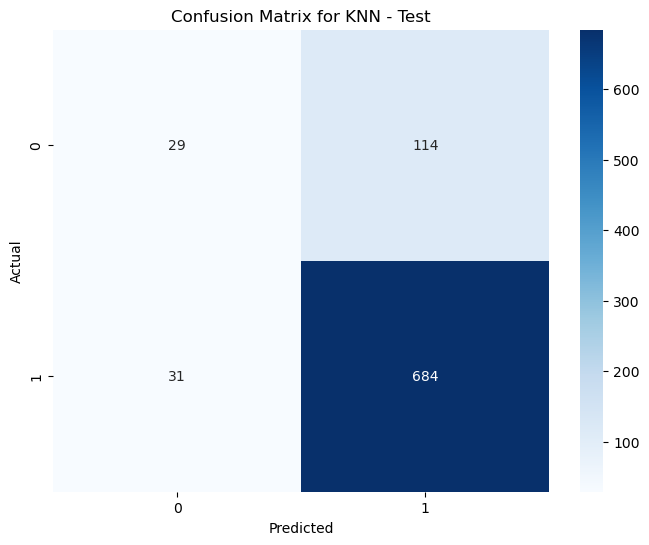

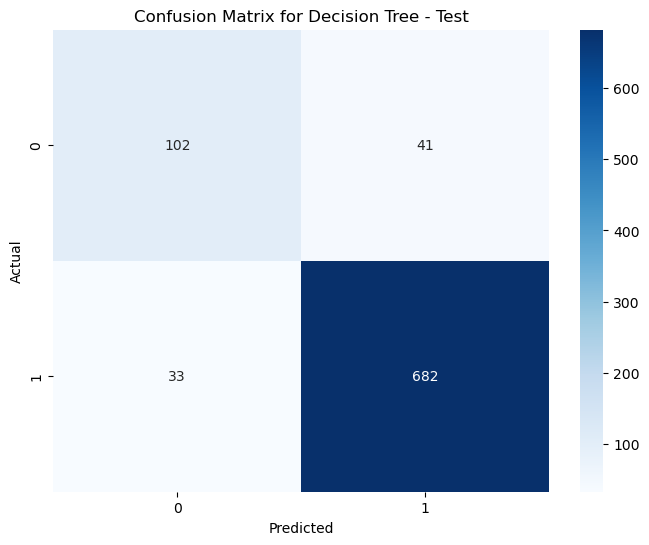

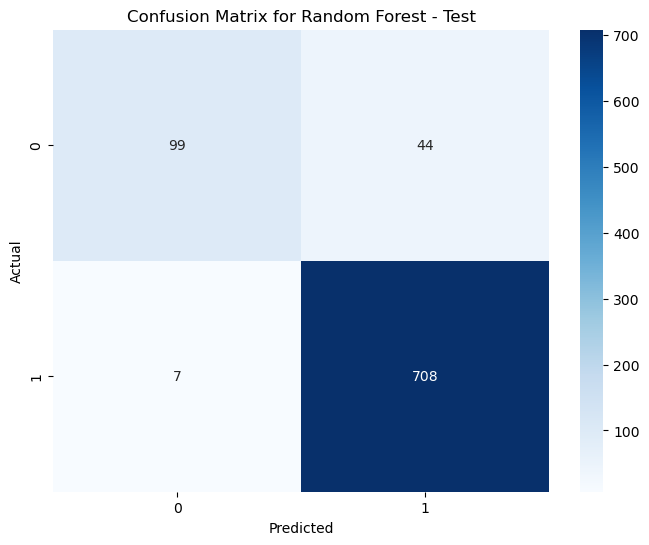

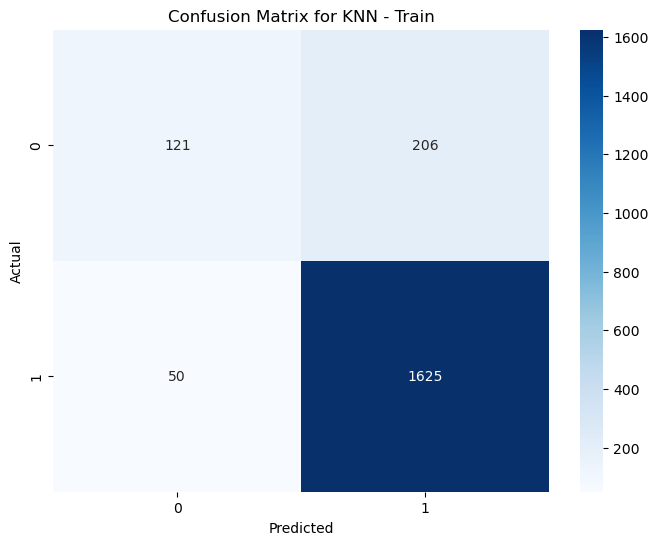

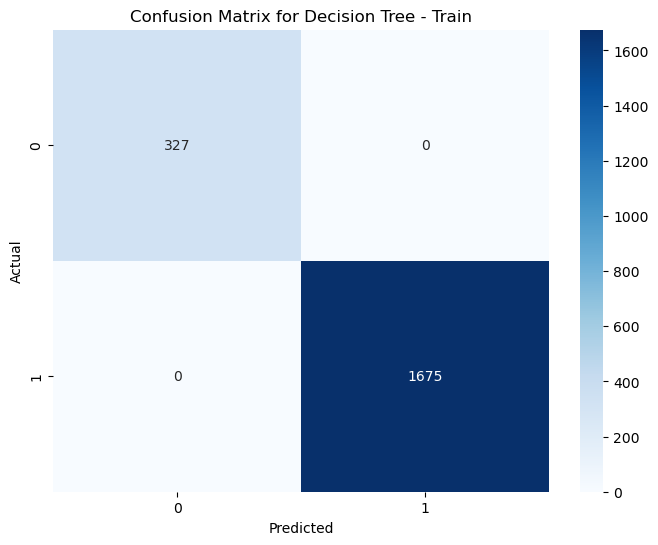

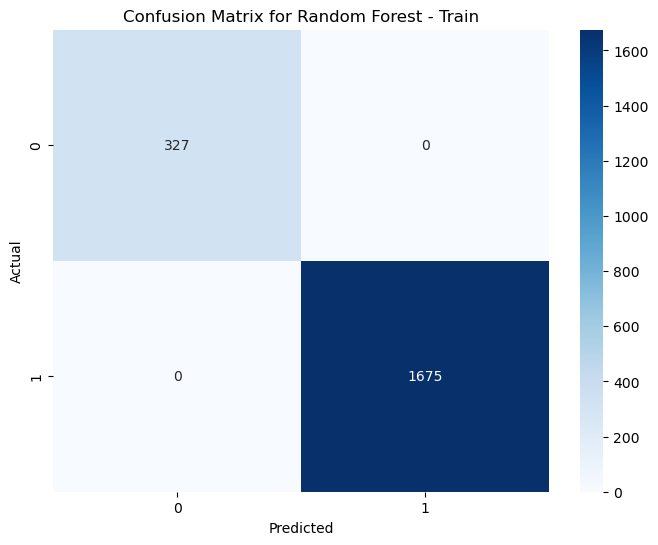

KNN Accuracy - Test: 0.831002331002331
Decision Tree Accuracy - Test: 0.9137529137529138
Random Forest Accuracy - Test: 0.9405594405594405
KNN Accuracy - Train: 0.8721278721278721
Decision Tree Accuracy - Train: 1.0
Random Forest Accuracy - Train: 1.0


In [61]:
# Initialize the models
knn_model = KNeighborsClassifier()
dt_model = DecisionTreeClassifier()
rf_model = RandomForestClassifier()

# Model training
knn_model.fit(x_train, y_train)
dt_model.fit(x_train, y_train)
rf_model.fit(x_train, y_train)

# Make predictions for both test and train sets
y_pred_knn_test = knn_model.predict(x_test)
y_pred_dt_test = dt_model.predict(x_test)
y_pred_rf_test = rf_model.predict(x_test)

y_pred_knn_train = knn_model.predict(x_train)
y_pred_dt_train = dt_model.predict(x_train)
y_pred_rf_train = rf_model.predict(x_train)

# Calculate confusion matrices for both test and train sets
cm_knn_test = confusion_matrix(y_test, y_pred_knn_test)
cm_dt_test = confusion_matrix(y_test, y_pred_dt_test)
cm_rf_test = confusion_matrix(y_test, y_pred_rf_test)

cm_knn_train = confusion_matrix(y_train, y_pred_knn_train)
cm_dt_train = confusion_matrix(y_train, y_pred_dt_train)
cm_rf_train = confusion_matrix(y_train, y_pred_rf_train)

# Function to plot confusion matrix
def plot_confusion_matrix(cm, model_name, data_type):
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix for {model_name} - {data_type}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

# Plot confusion matrices for both test and train sets
plot_confusion_matrix(cm_knn_test, 'KNN', 'Test')
plot_confusion_matrix(cm_dt_test, 'Decision Tree', 'Test')
plot_confusion_matrix(cm_rf_test, 'Random Forest', 'Test')

plot_confusion_matrix(cm_knn_train, 'KNN', 'Train')
plot_confusion_matrix(cm_dt_train, 'Decision Tree', 'Train')
plot_confusion_matrix(cm_rf_train, 'Random Forest', 'Train')

# Calculate and print the accuracy all model on both test and train sets
accuracy_knn_test = accuracy_score(y_test, y_pred_knn_test)
accuracy_dt_test = accuracy_score(y_test, y_pred_dt_test)
accuracy_rf_test = accuracy_score(y_test, y_pred_rf_test)

accuracy_knn_train = accuracy_score(y_train, y_pred_knn_train)
accuracy_dt_train = accuracy_score(y_train, y_pred_dt_train)
accuracy_rf_train = accuracy_score(y_train, y_pred_rf_train)

print(f"KNN Accuracy - Test: {accuracy_knn_test}")
print(f"Decision Tree Accuracy - Test: {accuracy_dt_test}")
print(f"Random Forest Accuracy - Test: {accuracy_rf_test}")

print(f"KNN Accuracy - Train: {accuracy_knn_train}")
print(f"Decision Tree Accuracy - Train: {accuracy_dt_train}")
print(f"Random Forest Accuracy - Train: {accuracy_rf_train}")




In [62]:



# Print classification report for the test set
print("Classification Report for KNN - Test Set:")
print(classification_report(y_test, y_pred_knn_test))

print("Classification Report for Decision Tree - Test Set:")
print(classification_report(y_test, y_pred_dt_test))

print("Classification Report for Random Forest - Test Set:")
print(classification_report(y_test, y_pred_rf_test))

# Print classification reports for the training set
print("Classification Report for KNN - Train Set:")
print(classification_report(y_train, y_pred_knn_train))

print("Classification Report for Decision Tree - Train Set:")
print(classification_report(y_train, y_pred_dt_train))

print("Classification Report for Random Forest - Train Set:")
print(classification_report(y_train, y_pred_rf_train))

Classification Report for KNN - Test Set:
              precision    recall  f1-score   support

           0       0.48      0.20      0.29       143
           1       0.86      0.96      0.90       715

    accuracy                           0.83       858
   macro avg       0.67      0.58      0.59       858
weighted avg       0.79      0.83      0.80       858

Classification Report for Decision Tree - Test Set:
              precision    recall  f1-score   support

           0       0.76      0.71      0.73       143
           1       0.94      0.95      0.95       715

    accuracy                           0.91       858
   macro avg       0.85      0.83      0.84       858
weighted avg       0.91      0.91      0.91       858

Classification Report for Random Forest - Test Set:
              precision    recall  f1-score   support

           0       0.93      0.69      0.80       143
           1       0.94      0.99      0.97       715

    accuracy                        

The accuracy of the neural network model on the training data is: 0.8431568431568431
The accuracy of the neural network model on the test data is: 0.8356643356643356


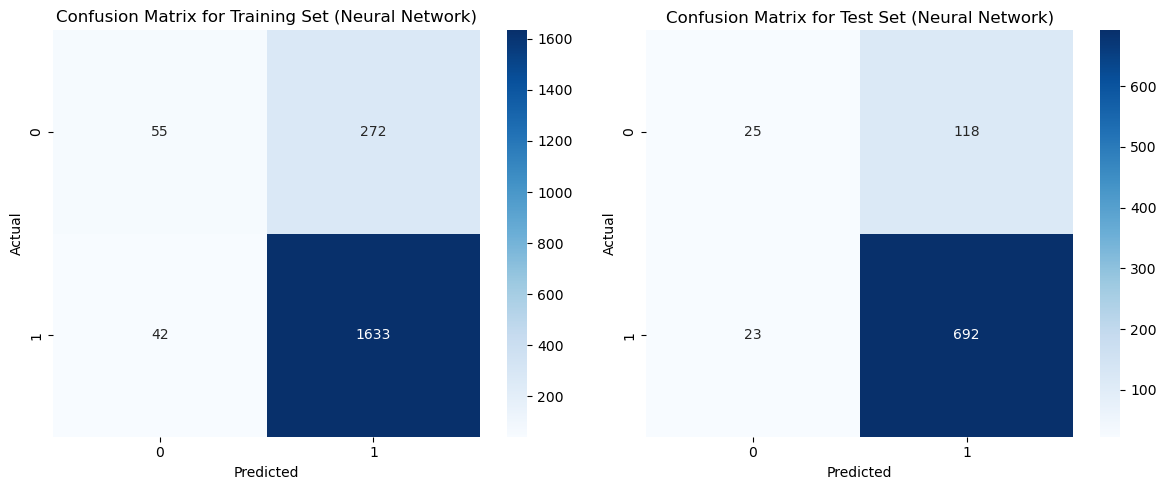

In [63]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix




# Initialize model
neural_network_model = MLPClassifier()

# Fit the model on the training data
neural_network_model.fit(x_train, y_train)

# Generate predictions for both train and test sets
y_predict_train_nn = neural_network_model.predict(x_train)
y_predict_test_nn = neural_network_model.predict(x_test)

# Calculate the accuracy of the model on both train and test sets
accuracy_train_nn = accuracy_score(y_train, y_predict_train_nn)
accuracy_test_nn = accuracy_score(y_test, y_predict_test_nn)

# Print the accuracy for both train and test sets
print(f"The accuracy of the neural network model on the training data is: {accuracy_train_nn}")
print(f"The accuracy of the neural network model on the test data is: {accuracy_test_nn}")

# Create confusion matrices for both train and test sets
confusion_matrix_train_nn = confusion_matrix(y_train, y_predict_train_nn)
confusion_matrix_test_nn = confusion_matrix(y_test, y_predict_test_nn)

# Create heatmap for the confusion matrices
plt.figure(figsize=(12, 5))

# Heatmap for the training set
plt.subplot(1, 2, 1)
sns.heatmap(confusion_matrix_train_nn, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix for Training Set (Neural Network)')
plt.xlabel('Predicted')
plt.ylabel('Actual')

# Heatmap for the test set
plt.subplot(1, 2, 2)
sns.heatmap(confusion_matrix_test_nn, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix for Test Set (Neural Network)')
plt.xlabel('Predicted')
plt.ylabel('Actual')

# Show the heatmap
plt.tight_layout()
plt.show()

The accuracy of the neural network model on the training data is: 0.7767232767232767
The accuracy of the neural network model on the test data is: 0.7645687645687645


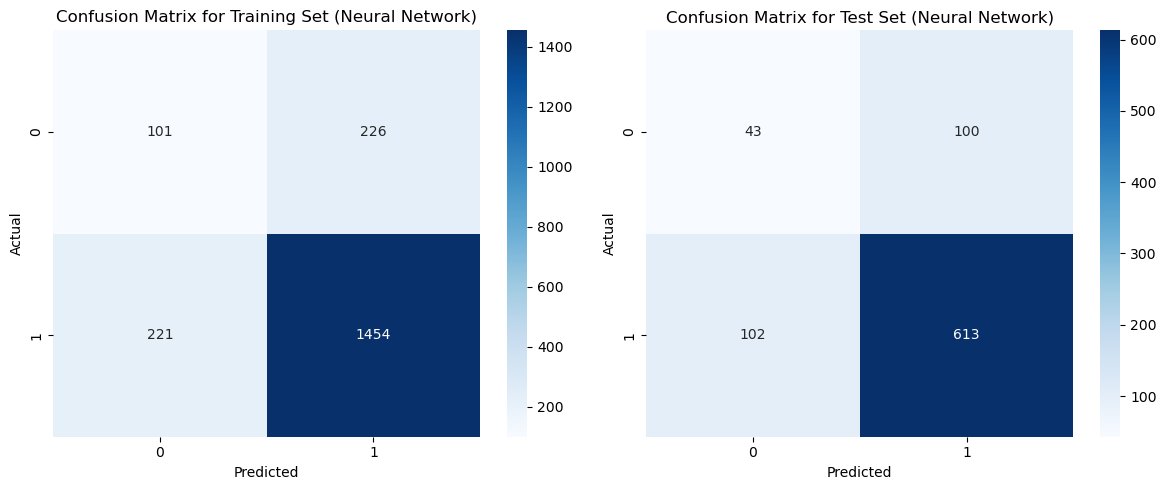

Classification Report for Neural Network Model:
              precision    recall  f1-score   support

           0       0.31      0.31      0.31       327
           1       0.87      0.87      0.87      1675

    accuracy                           0.78      2002
   macro avg       0.59      0.59      0.59      2002
weighted avg       0.78      0.78      0.78      2002

------------------------------------------------
              precision    recall  f1-score   support

           0       0.30      0.30      0.30       143
           1       0.86      0.86      0.86       715

    accuracy                           0.76       858
   macro avg       0.58      0.58      0.58       858
weighted avg       0.77      0.76      0.77       858



In [64]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Initialize model
neural_network_model = MLPClassifier()

# Fit the model on the training data
neural_network_model.fit(x_train, y_train)

# Generate predictions for both train and test sets
y_predict_train_nn = neural_network_model.predict(x_train)
y_predict_test_nn = neural_network_model.predict(x_test)

# Calculate the accuracy of the model on both train and test sets
accuracy_train_nn = accuracy_score(y_train, y_predict_train_nn)
accuracy_test_nn = accuracy_score(y_test, y_predict_test_nn)

# Print the accuracy for both train and test sets
print(f"The accuracy of the neural network model on the training data is: {accuracy_train_nn}")
print(f"The accuracy of the neural network model on the test data is: {accuracy_test_nn}")

# Create confusion matrices for both train and test sets
confusion_matrix_train_nn = confusion_matrix(y_train, y_predict_train_nn)
confusion_matrix_test_nn = confusion_matrix(y_test, y_predict_test_nn)

# Create heatmap for the confusion matrices
plt.figure(figsize=(12, 5))

# Heatmap for the training set
plt.subplot(1, 2, 1)
sns.heatmap(confusion_matrix_train_nn, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix for Training Set (Neural Network)')
plt.xlabel('Predicted')
plt.ylabel('Actual')

# Heatmap for the test set
plt.subplot(1, 2, 2)
sns.heatmap(confusion_matrix_test_nn, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix for Test Set (Neural Network)')
plt.xlabel('Predicted')
plt.ylabel('Actual')

# Show the heatmap
plt.tight_layout()
plt.show()

# Print classification report for the neural network model
print("Classification Report for Neural Network Model:")
print(classification_report(y_train, y_predict_train_nn))
print("------------------------------------------------")
print(classification_report(y_test, y_predict_test_nn))

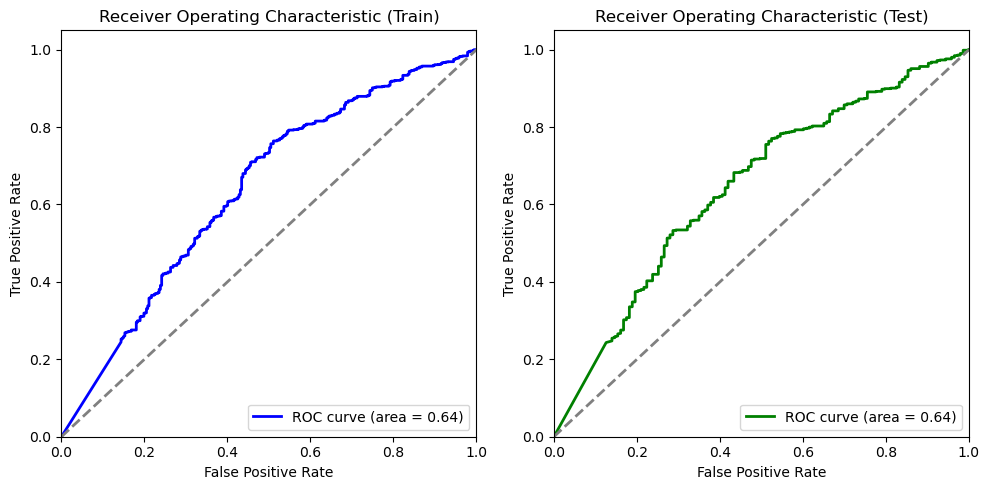

The AUC for the training set is: 0.6387000775936829
The AUC for the test set is: 0.6443591373661304


In [65]:
from sklearn.metrics import roc_curve, auc

# Generate predicted probabilities for both train and test sets
y_probs_train_nn = neural_network_model.predict_proba(x_train)[:, 1]
y_probs_test_nn = neural_network_model.predict_proba(x_test)[:, 1]

# Calculate the ROC curve and AUC for the training set
fpr_train, tpr_train, _ = roc_curve(y_train, y_probs_train_nn)
roc_auc_train = auc(fpr_train, tpr_train)

# Calculate the ROC curve and AUC for the test set
fpr_test, tpr_test, _ = roc_curve(y_test, y_probs_test_nn)
roc_auc_test = auc(fpr_test, tpr_test)

# Plot ROC curve for training set
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.plot(fpr_train, tpr_train, color='blue', lw=2, label='ROC curve (area = %0.2f)' % roc_auc_train)
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (Train)')
plt.legend(loc="lower right")

# Plot ROC curve for test set
plt.subplot(1, 2, 2)
plt.plot(fpr_test, tpr_test, color='green', lw=2, label='ROC curve (area = %0.2f)' % roc_auc_test)
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (Test)')
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()

# Print AUC for both train and test sets
print(f"The AUC for the training set is: {roc_auc_train}")
print(f"The AUC for the test set is: {roc_auc_test}")

In [66]:

from scipy.stats import chi2_contingency

# Assuming 'df' is a pandas DataFrame containing the dataset
# and the variables are categorical columns in 'df'

# List of variables to calculate chi-squared scores for
variables = [
    'Result', 'Avg_team_Age', 'Match_light_type',
    'Match_format', 'Bowlers_in_team',
    'All_rounder_in_team', 'First_selection', 'Opponent', 'Season',
    'Audience_number', 'Offshore', 'Max_run_scored_1over',
    'Max_wicket_taken_1over', 'Extra_bowls_bowled', 'Min_run_given_1over',
    'Min_run_scored_1over', 'Max_run_given_1over', 'extra_bowls_opponent',
    'player_highest_run', 'Players_scored_zero', 'player_highest_wicket'
]

# Dictionary to store chi-squared scores
chi_squared_scores = {}

# Calculate chi-squared score for each variable
for variable in variables:
    # Create a contingency table
    contingency_table = pd.crosstab(df[variable], df['Result'])
    # Perform chi-squared test
    chi2, p, dof, expected = chi2_contingency(contingency_table)
    # Store the chi-squared score
    chi_squared_scores[variable] = chi2

# Print the chi-squared scores
for variable, score in chi_squared_scores.items():
    print(f"Chi score for {variable}: {score}")

# Assuming 'Result' is the target variable
# If 'Result' is not the target variable, replace it with the actual target variable in the crosstab 

Chi score for Result: 2852.722875863757
Chi score for Avg_team_Age: 137.94008781570903
Chi score for Match_light_type: 45.6708132706161
Chi score for Match_format: 21.233581594465484
Chi score for Bowlers_in_team: 6.1063563405020025
Chi score for All_rounder_in_team: 39.71116580295492
Chi score for First_selection: 2.5578420486314277
Chi score for Opponent: 176.33236522573972
Chi score for Season: 93.9279429970015
Chi score for Audience_number: 2487.264955933411
Chi score for Offshore: 166.8614098581564
Chi score for Max_run_scored_1over: 23.118715986846755
Chi score for Max_wicket_taken_1over: 10.9304962627169
Chi score for Extra_bowls_bowled: 241.7397196208537
Chi score for Min_run_given_1over: 43.82178622279596
Chi score for Min_run_scored_1over: 28.84679372105755
Chi score for Max_run_given_1over: 80.83583662324537
Chi score for extra_bowls_opponent: 125.18736626345965
Chi score for player_highest_run: 139.16360828039507
Chi score for Players_scored_zero: 54.77004511616919
Chi scor

In [67]:
from sklearn.ensemble import BaggingClassifier

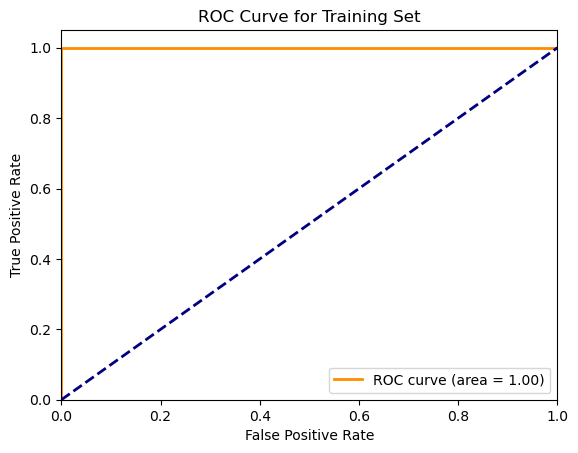

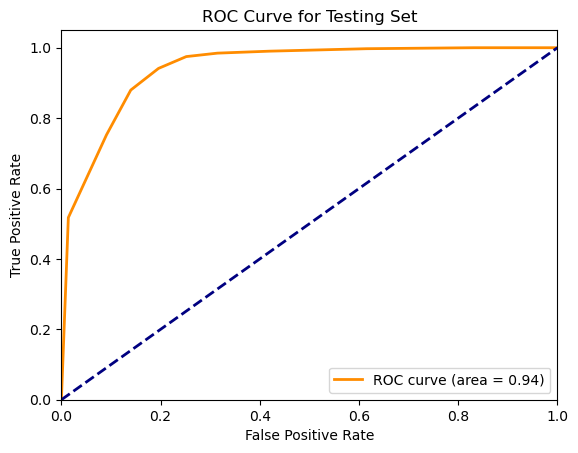

Classification Report for Training Set:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       327
           1       1.00      1.00      1.00      1675

    accuracy                           1.00      2002
   macro avg       1.00      1.00      1.00      2002
weighted avg       1.00      1.00      1.00      2002

Classification Report for Testing Set:
              precision    recall  f1-score   support

           0       0.86      0.75      0.80       143
           1       0.95      0.97      0.96       715

    accuracy                           0.94       858
   macro avg       0.90      0.86      0.88       858
weighted avg       0.94      0.94      0.94       858



In [68]:
# Initialize the Bagging Classifier
bagging_clf = BaggingClassifier(random_state=42)

# Fit the model on the training data
bagging_clf.fit(x_train, y_train)

#  the training data
y_train_pred = bagging_clf.predict(x_train)
y_train_proba = bagging_clf.predict_proba(x_train)[:, 1]

#  testing data
y_test_pred = bagging_clf.predict(x_test)
y_test_proba = bagging_clf.predict_proba(x_test)[:, 1]

# Calculate confusion matrices for the training and testing data
conf_matrix_train = confusion_matrix(y_train, y_train_pred)
conf_matrix_test = confusion_matrix(y_test, y_test_pred)

# plot ROC curve and calculate AUC
def plot_roc_curve(y_true, y_scores, set_name):
    fpr, tpr, _ = roc_curve(y_true, y_scores)
    roc_auc = auc(fpr, tpr)
    plt.figure()
    plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curve for {set_name} Set')
    plt.legend(loc="lower right")
    plt.show()

# Plot ROC curve and calculate AUC for training set
plot_roc_curve(y_train, y_train_proba, 'Training')

# Plot ROC curve and calculate AUC for testing set
plot_roc_curve(y_test, y_test_proba, 'Testing')

# Predict on the training data
y_train_pred = bagging_clf.predict(x_train)

# Predict on the testing data
y_test_pred = bagging_clf.predict(x_test)

# Print classification report for the training set
print("Classification Report for Training Set:")
print(classification_report(y_train, y_train_pred))

# Print classification report for the testing set
print("Classification Report for Testing Set:")
print(classification_report(y_test, y_test_pred))

In [69]:
## SMOTE 

In [70]:
from imblearn.over_sampling import SMOTE

# Assuming X and y are your features and target variable respectively
# Create an instance of SMOTE
smote = SMOTE(sampling_strategy='minority', random_state=42)

# Fit SMOTE to your data and resample
x_resampled, y_resampled = smote.fit_resample(x, y)

# Check the class distribution after resampling
print(y_resampled.value_counts())

0    2390
1    2390
Name: Result, dtype: int64


Decision Tree Classifier - Test data:
[[455  14]
 [ 32 455]]
Decision Tree Classifier - Train data:
[[1921    0]
 [   0 1903]]
Random Forest Classifier - Test data:
[[464   5]
 [  5 482]]
Random Forest Classifier - Train data:
[[1921    0]
 [   0 1903]]


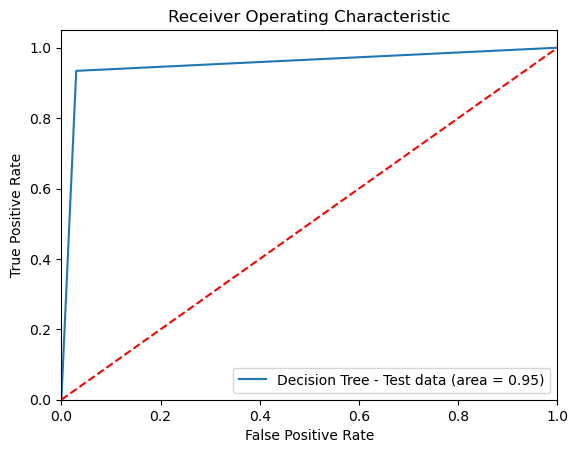

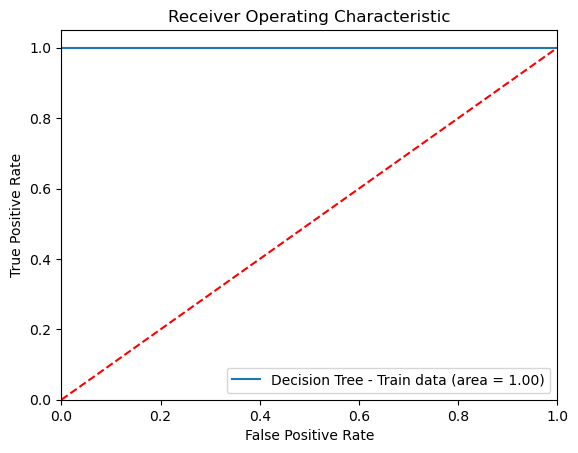

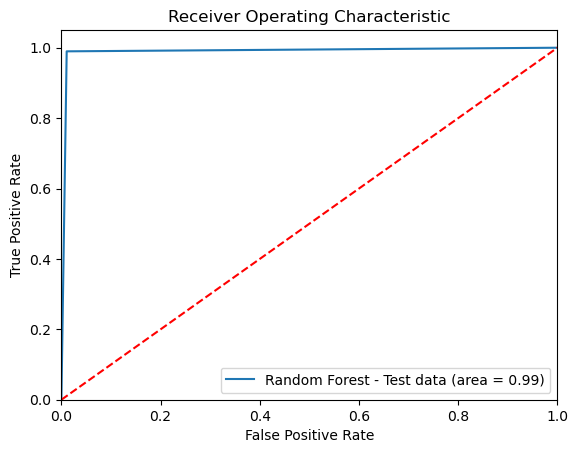

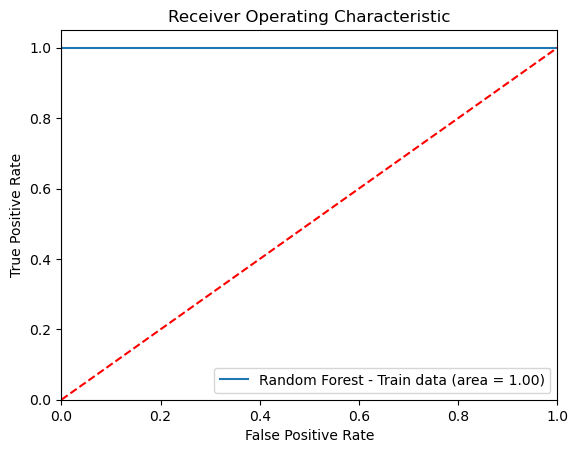

In [71]:
# Running models post SMOTE treatment 
#  x_resampled and y_resampled are your features and target variable respectively
# Splitting the resampled data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(x_resampled, y_resampled, test_size=0.2, random_state=42)

# Create an instance of DecisionTreeClassifier
dt = DecisionTreeClassifier(random_state=42)

# Fit the model to your data
dt.fit(X_train, y_train)

# Predict the labels of the test set
y_pred_dt = dt.predict(X_test)

# Print the confusion matrix for the test data
print("Decision Tree Classifier - Test data:")
print(confusion_matrix(y_test, y_pred_dt))

# Predict the labels of the train set
y_pred_dt_train = dt.predict(X_train)

# Print the confusion matrix for the train data
print("Decision Tree Classifier - Train data:")
print(confusion_matrix(y_train, y_pred_dt_train))

# Create an instance of RandomForestClassifier
rf = RandomForestClassifier(random_state=42)

# Fit the model to your data
rf.fit(X_train, y_train)

# Predict the labels of the test set
y_pred_rf = rf.predict(X_test)

# Print the confusion matrix for the test data
print("Random Forest Classifier - Test data:")
print(confusion_matrix(y_test, y_pred_rf))

# Predict the labels of the train set
y_pred_rf_train = rf.predict(X_train)

# Print the confusion matrix for the train data
print("Random Forest Classifier - Train data:")
print(confusion_matrix(y_train, y_pred_rf_train))

# Function to plot ROC curve and calculate AUC
def plot_roc_auc(y_true, y_pred, model_name):
    fpr, tpr, _ = roc_curve(y_true, y_pred)
    roc_auc = auc(fpr, tpr)
    plt.figure()
    plt.plot(fpr, tpr, label=f'{model_name} (area = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1],'r--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

# Plot ROC curve and calculate AUC for Decision Tree Classifier
plot_roc_auc(y_test, y_pred_dt, 'Decision Tree - Test data')
plot_roc_auc(y_train, y_pred_dt_train, 'Decision Tree - Train data')

# Plot ROC curve and calculate AUC for Random Forest Classifier
plot_roc_auc(y_test, y_pred_rf, 'Random Forest - Test data')
plot_roc_auc(y_train, y_pred_rf_train, 'Random Forest - Train data')

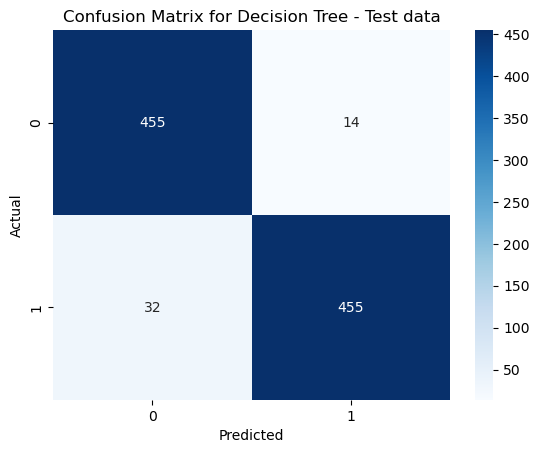

Classification Report for Decision Tree - Test data:

              precision    recall  f1-score   support

           0       0.93      0.97      0.95       469
           1       0.97      0.93      0.95       487

    accuracy                           0.95       956
   macro avg       0.95      0.95      0.95       956
weighted avg       0.95      0.95      0.95       956



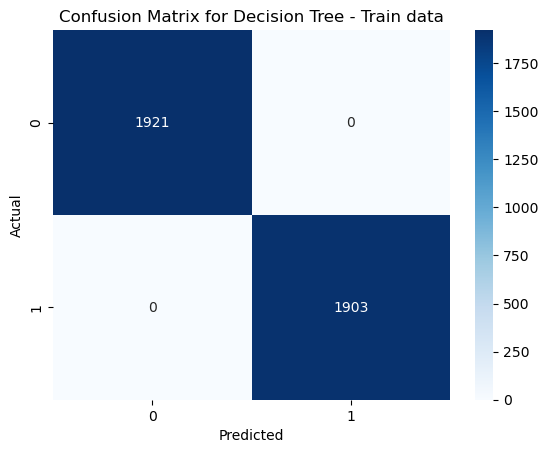

Classification Report for Decision Tree - Train data:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1921
           1       1.00      1.00      1.00      1903

    accuracy                           1.00      3824
   macro avg       1.00      1.00      1.00      3824
weighted avg       1.00      1.00      1.00      3824



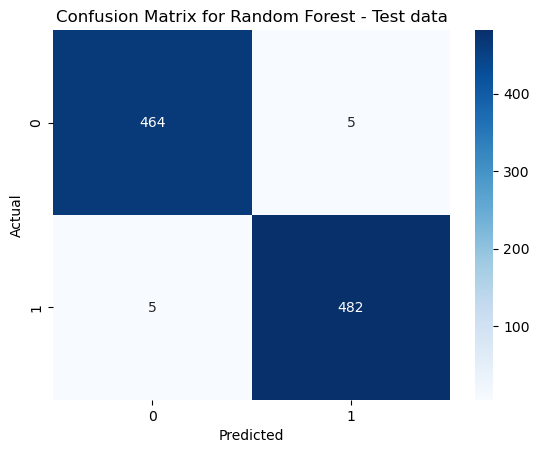

Classification Report for Random Forest - Test data:

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       469
           1       0.99      0.99      0.99       487

    accuracy                           0.99       956
   macro avg       0.99      0.99      0.99       956
weighted avg       0.99      0.99      0.99       956



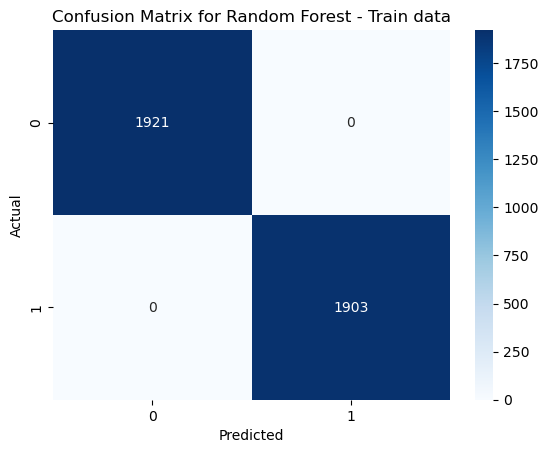

Classification Report for Random Forest - Train data:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1921
           1       1.00      1.00      1.00      1903

    accuracy                           1.00      3824
   macro avg       1.00      1.00      1.00      3824
weighted avg       1.00      1.00      1.00      3824



In [72]:

#  plot confusion matrix as a heatmap and print classification report
def plot_confusion_matrix_heatmap_and_report(y_true, y_pred, model_name):
    # Plot confusion matrix
    conf_mat = confusion_matrix(y_true, y_pred)
    sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(f'Confusion Matrix for {model_name}')
    plt.show()

    # Print classification report
    print(f"Classification Report for {model_name}:\n")
    print(classification_report(y_true, y_pred))

# Plot confusion matrix heatmap and print classification report for Decision Tree Classifier
plot_confusion_matrix_heatmap_and_report(y_test, y_pred_dt, 'Decision Tree - Test data')
plot_confusion_matrix_heatmap_and_report(y_train, y_pred_dt_train, 'Decision Tree - Train data')

# Plot confusion matrix heatmap and print classification report for Random Forest Classifier
plot_confusion_matrix_heatmap_and_report(y_test, y_pred_rf, 'Random Forest - Test data')
plot_confusion_matrix_heatmap_and_report(y_train, y_pred_rf_train, 'Random Forest - Train data')

The accuracy of the logistic regression model on the training data is: 0.6845188284518828
The accuracy of the logistic regression model on the test data is: 0.6788702928870293


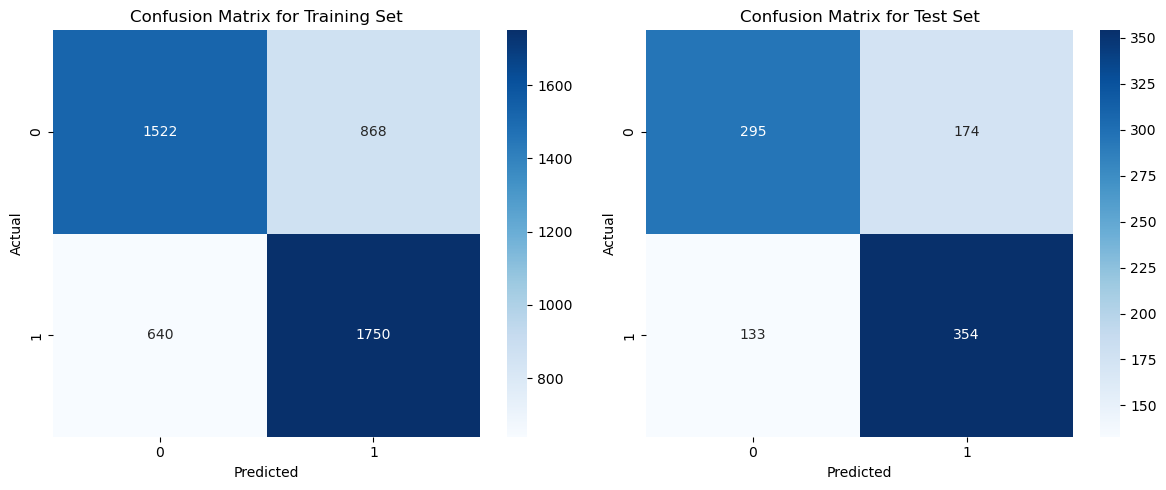

In [73]:
# Create a Logistic Regression model to test post SMOTE
logistic_model = LogisticRegression()

# Train the model using the resampled training data
logistic_model.fit(x_resampled, y_resampled)

# Generate predictions for both train and test sets
y_predict_train = logistic_model.predict(x_resampled)
y_predict_test = logistic_model.predict(X_test)

# Calculate the accuracy of the model on both train and test sets
accuracy_train = accuracy_score(y_resampled, y_predict_train)
accuracy_test = accuracy_score(y_test, y_predict_test)

# Print the accuracy for both train and test sets
print(f"The accuracy of the logistic regression model on the training data is: {accuracy_train}")
print(f"The accuracy of the logistic regression model on the test data is: {accuracy_test}")

# Create confusion matrices for both train and test sets
confusion_matrix_train = confusion_matrix(y_resampled, y_predict_train)
confusion_matrix_test = confusion_matrix(y_test, y_predict_test)

# Create heatmaps for the confusion matrices
plt.figure(figsize=(12, 5))

# Heatmap for the training set
plt.subplot(1, 2, 1)
sns.heatmap(confusion_matrix_train, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix for Training Set')
plt.xlabel('Predicted')
plt.ylabel('Actual')

# Heatmap for the test set
plt.subplot(1, 2, 2)
sns.heatmap(confusion_matrix_test, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix for Test Set')
plt.xlabel('Predicted')
plt.ylabel('Actual')

# Show the heatmaps
plt.tight_layout()
plt.show()

In [74]:
# Generate predictions for both train and test sets
y_predict_train = logistic_model.predict(x_resampled)
y_predict_test = logistic_model.predict(X_test)

# Print the classification report for both train and test sets
print("Classification report for the training set post SMOTE:")
print(classification_report(y_resampled, y_predict_train))

print("Classification report for the test set post SMOTE:")
print(classification_report(y_test, y_predict_test))

Classification report for the training set post SMOTE:
              precision    recall  f1-score   support

           0       0.70      0.64      0.67      2390
           1       0.67      0.73      0.70      2390

    accuracy                           0.68      4780
   macro avg       0.69      0.68      0.68      4780
weighted avg       0.69      0.68      0.68      4780

Classification report for the test set post SMOTE:
              precision    recall  f1-score   support

           0       0.69      0.63      0.66       469
           1       0.67      0.73      0.70       487

    accuracy                           0.68       956
   macro avg       0.68      0.68      0.68       956
weighted avg       0.68      0.68      0.68       956



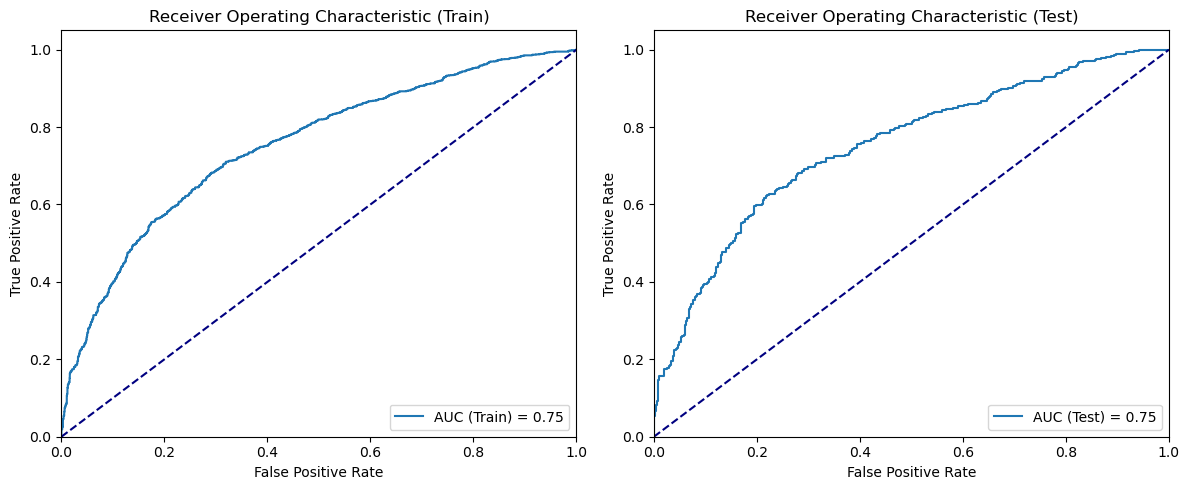

In [75]:
# Calculate the probabilities for the train set
y_prob_train = logistic_model.predict_proba(x_resampled)[:, 1]

# Calculate the probabilities for the test set
y_prob_test = logistic_model.predict_proba(X_test)[:, 1]

# Calculate the ROC curve for the train set
fpr_train, tpr_train, _ = roc_curve(y_resampled, y_prob_train)

# Calculate the ROC curve for the test set
fpr_test, tpr_test, _ = roc_curve(y_test, y_prob_test)

# Calculate the AUC for the train set
auc_train = roc_auc_score(y_resampled, y_prob_train)

# Calculate the AUC for the test set
auc_test = roc_auc_score(y_test, y_prob_test)

# Plot the ROC curve for the train set
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(fpr_train, tpr_train, label=f"AUC (Train) = {auc_train:.2f}")
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (Train)')
plt.legend(loc="lower right")

# Plot the ROC curve for the test set
plt.subplot(1, 2, 2)
plt.plot(fpr_test, tpr_test, label=f"AUC (Test) = {auc_test:.2f}")
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (Test)')
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()

The accuracy of the LDA model on the training data is: 0.7640167364016737
The accuracy of the LDA model on the test data is: 0.7667364016736402


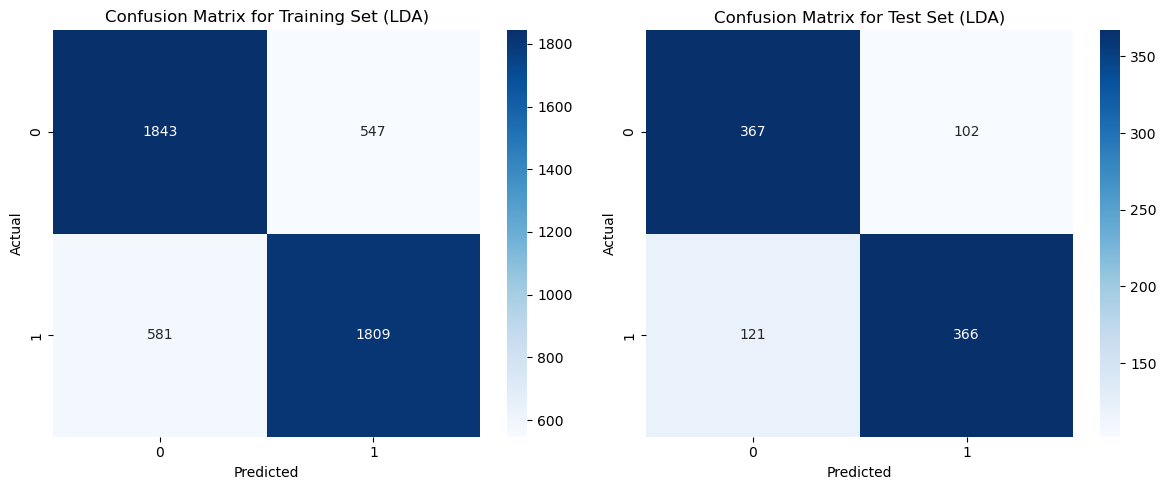

Classification Report for Training Set post SMOTE (LDA):
              precision    recall  f1-score   support

           0       0.76      0.77      0.77      2390
           1       0.77      0.76      0.76      2390

    accuracy                           0.76      4780
   macro avg       0.76      0.76      0.76      4780
weighted avg       0.76      0.76      0.76      4780


Classification Report for Test Set post SMOTE (LDA):
              precision    recall  f1-score   support

           0       0.75      0.78      0.77       469
           1       0.78      0.75      0.77       487

    accuracy                           0.77       956
   macro avg       0.77      0.77      0.77       956
weighted avg       0.77      0.77      0.77       956



In [76]:
## LDA for reference of Analysis POST SMOTE

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Create LDA model
lda_model = LinearDiscriminantAnalysis()

# Train the model using the resampled training data
lda_model.fit(x_resampled, y_resampled)

# Generate predictions for both train and test sets
y_predict_train_lda = lda_model.predict(x_resampled)
y_predict_test_lda = lda_model.predict(X_test)

# Calculate the accuracy of the model on both train and test sets
accuracy_train_lda = accuracy_score(y_resampled, y_predict_train_lda)
accuracy_test_lda = accuracy_score(y_test, y_predict_test_lda)

# Print the accuracy for both train and test sets
print(f"The accuracy of the LDA model on the training data is: {accuracy_train_lda}")
print(f"The accuracy of the LDA model on the test data is: {accuracy_test_lda}")

# Create confusion matrices for both train and test sets
confusion_matrix_train_lda = confusion_matrix(y_resampled, y_predict_train_lda)
confusion_matrix_test_lda = confusion_matrix(y_test, y_predict_test_lda)

# Create heatmaps for the confusion matrices
plt.figure(figsize=(12, 5))

# Heatmap for the training set
plt.subplot(1, 2, 1)
sns.heatmap(confusion_matrix_train_lda, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix for Training Set (LDA)')
plt.xlabel('Predicted')
plt.ylabel('Actual')

# Heatmap for the test set
plt.subplot(1, 2, 2)
sns.heatmap(confusion_matrix_test_lda, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix for Test Set (LDA)')
plt.xlabel('Predicted')
plt.ylabel('Actual')

# Show the heatmaps
plt.tight_layout()
plt.show()

# Classification report for both train and test sets
print("Classification Report for Training Set post SMOTE (LDA):")
print(classification_report(y_resampled, y_predict_train_lda))

print("\nClassification Report for Test Set post SMOTE (LDA):")
print(classification_report(y_test, y_predict_test_lda))

The accuracy of the LDA model on the training data is: 0.8556443556443556
The accuracy of the LDA model on the test data is: 0.8438228438228438


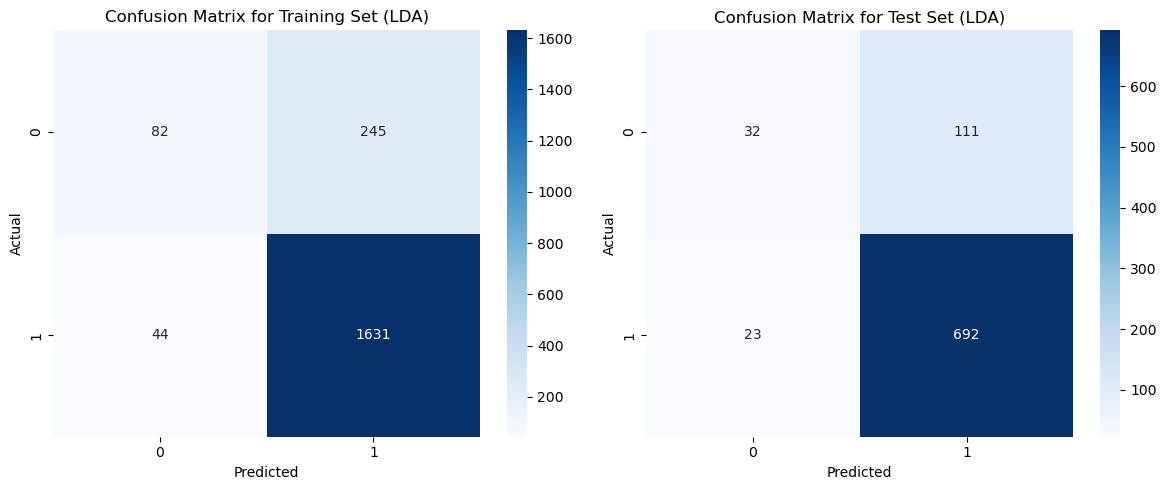

Classification Report for Training Set pre SMOTE (LDA):
              precision    recall  f1-score   support

           0       0.65      0.25      0.36       327
           1       0.87      0.97      0.92      1675

    accuracy                           0.86      2002
   macro avg       0.76      0.61      0.64      2002
weighted avg       0.83      0.86      0.83      2002


Classification Report for Test Set pre SMOTE (LDA):
              precision    recall  f1-score   support

           0       0.58      0.22      0.32       143
           1       0.86      0.97      0.91       715

    accuracy                           0.84       858
   macro avg       0.72      0.60      0.62       858
weighted avg       0.82      0.84      0.81       858



In [77]:
# Pre SMOTE LDA model 

from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming x and y are your features and target variables respectively
# Split the data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42)

# Create LDA model
lda_model = LinearDiscriminantAnalysis()

# Train the model using the training data
lda_model.fit(x_train, y_train)

# Generate predictions for both train and test sets
y_predict_train_lda = lda_model.predict(x_train)
y_predict_test_lda = lda_model.predict(x_test)

# Calculate the accuracy of the model on both train and test sets
accuracy_train_lda = accuracy_score(y_train, y_predict_train_lda)
accuracy_test_lda = accuracy_score(y_test, y_predict_test_lda)

# Print the accuracy for both train and test sets
print(f"The accuracy of the LDA model on the training data is: {accuracy_train_lda}")
print(f"The accuracy of the LDA model on the test data is: {accuracy_test_lda}")

# Create confusion matrices for both train and test sets
confusion_matrix_train_lda = confusion_matrix(y_train, y_predict_train_lda)
confusion_matrix_test_lda = confusion_matrix(y_test, y_predict_test_lda)

# Create heatmaps for the confusion matrices
plt.figure(figsize=(12, 5))

# Heatmap for the training set
plt.subplot(1, 2, 1)
sns.heatmap(confusion_matrix_train_lda, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix for Training Set (LDA)')
plt.xlabel('Predicted')
plt.ylabel('Actual')

# Heatmap for the test set
plt.subplot(1, 2, 2)
sns.heatmap(confusion_matrix_test_lda, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix for Test Set (LDA)')
plt.xlabel('Predicted')
plt.ylabel('Actual')

# Show the heatmaps
plt.tight_layout()
plt.show()

# Classification report for both train and test sets
print("Classification Report for Training Set pre SMOTE (LDA):")
print(classification_report(y_train, y_predict_train_lda))

print("\nClassification Report for Test Set pre SMOTE (LDA):")
print(classification_report(y_test, y_predict_test_lda))

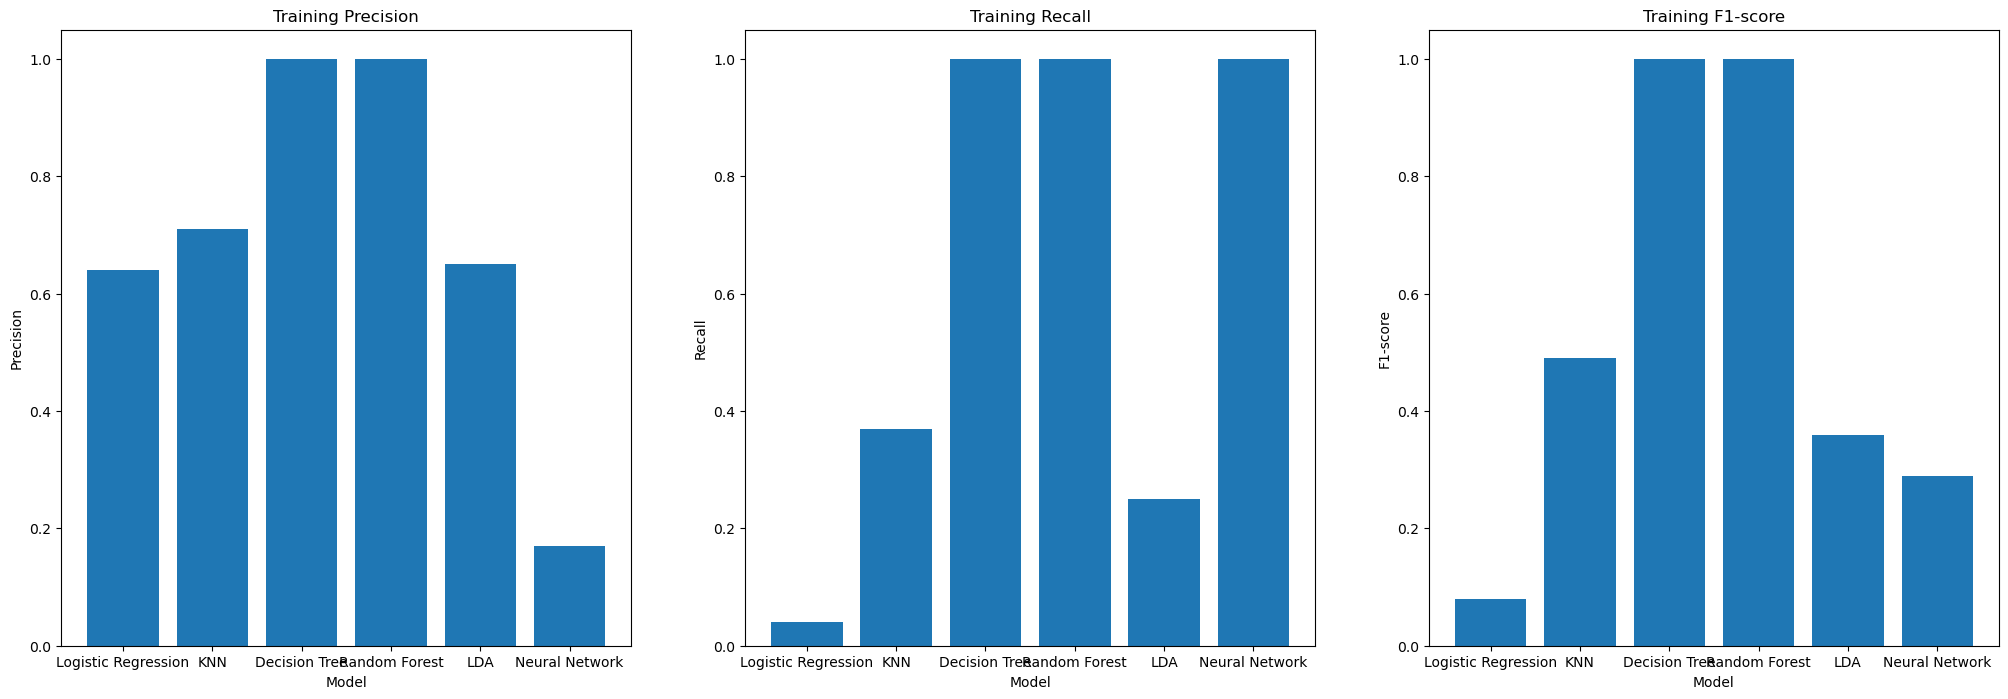

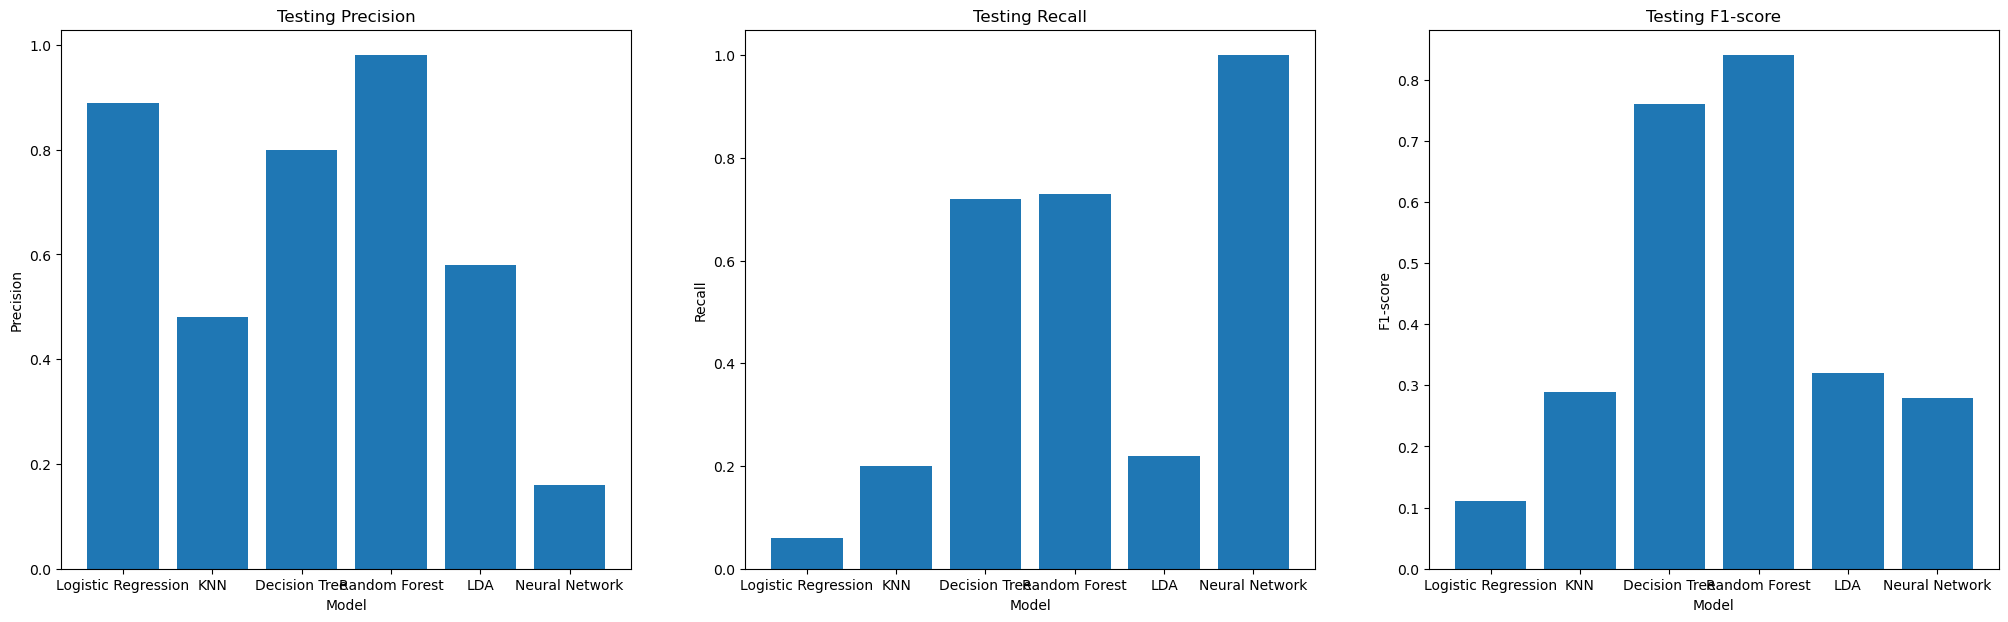

In [78]:
import matplotlib.pyplot as plt

# Define the data
models = ['Logistic Regression', 'KNN', 'Decision Tree', 'Random Forest', 'LDA', 'Neural Network']
train_precisions = [0.64, 0.71, 1.00, 1.00, 0.65, 0.17]
train_recalls = [0.04, 0.37, 1.00, 1.00, 0.25, 1.00]
train_f1s = [0.08, 0.49, 1.00, 1.00, 0.36, 0.29]
test_precisions = [0.89, 0.48, 0.80, 0.98, 0.58, 0.16]
test_recalls = [0.06, 0.20, 0.72, 0.73, 0.22, 1.00]
test_f1s = [0.11, 0.29, 0.76, 0.84, 0.32, 0.28]

# Create the figure and axis
fig, ax = plt.subplots(1, 3, figsize=(25, 8))

# Plot the training performance
ax[0].bar(models, train_precisions)
ax[0].set_title('Training Precision')
ax[0].set_xlabel('Model')
ax[0].set_ylabel('Precision')

ax[1].bar(models, train_recalls)
ax[1].set_title('Training Recall')
ax[1].set_xlabel('Model')
ax[1].set_ylabel('Recall')

ax[2].bar(models, train_f1s)
ax[2].set_title('Training F1-score')
ax[2].set_xlabel('Model')
ax[2].set_ylabel('F1-score')

# Plot the testing performance
fig, ax = plt.subplots(1, 3, figsize=(25, 7))

ax[0].bar(models, test_precisions)
ax[0].set_title('Testing Precision')
ax[0].set_xlabel('Model')
ax[0].set_ylabel('Precision')

ax[1].bar(models, test_recalls)
ax[1].set_title('Testing Recall')
ax[1].set_xlabel('Model')
ax[1].set_ylabel('Recall')

ax[2].bar(models, test_f1s)
ax[2].set_title('Testing F1-score')
ax[2].set_xlabel('Model')
ax[2].set_ylabel('F1-score')

# Show the plots
plt.show()

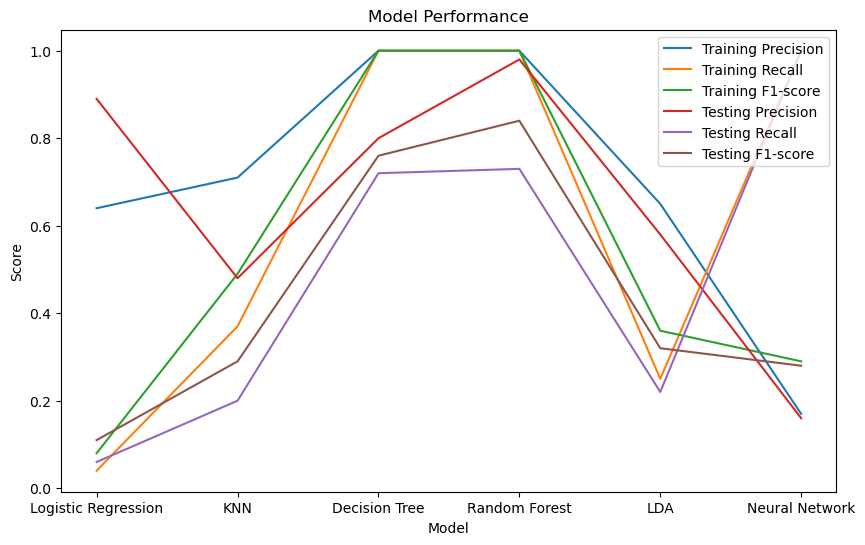

In [79]:
import matplotlib.pyplot as plt
import numpy as np

# Define the data
models = ['Logistic Regression', 'KNN', 'Decision Tree', 'Random Forest', 'LDA', 'Neural Network']
train_precisions = [0.64, 0.71, 1.00, 1.00, 0.65, 0.17]
train_recalls = [0.04, 0.37, 1.00, 1.00, 0.25, 1.00]
train_f1s = [0.08, 0.49, 1.00, 1.00, 0.36, 0.29]
test_precisions = [0.89, 0.48, 0.80, 0.98, 0.58, 0.16]
test_recalls = [0.06, 0.20, 0.72, 0.73, 0.22, 1.00]
test_f1s = [0.11, 0.29, 0.76, 0.84, 0.32, 0.28]

# Create the figure and axis
fig, ax = plt.subplots(1, 1, figsize=(10, 6))

# Plot the training performance
ax.plot(models, train_precisions, label='Training Precision')
ax.plot(models, train_recalls, label='Training Recall')
ax.plot(models, train_f1s, label='Training F1-score')

# Plot the testing performance
ax.plot(models, test_precisions, label='Testing Precision')
ax.plot(models, test_recalls, label='Testing Recall')
ax.plot(models, test_f1s, label='Testing F1-score')

# Set title and labels
ax.set_title('Model Performance')
ax.set_xlabel('Model')
ax.set_ylabel('Score')

# Legend
ax.legend(loc='upper right')

# Show the plot
plt.show()

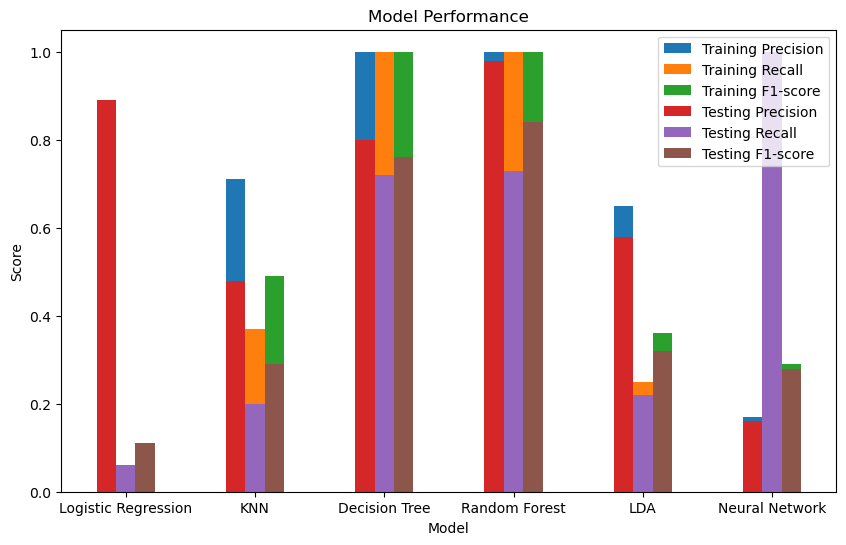

In [80]:
import matplotlib.pyplot as plt
import numpy as np

# Define the data
models = ['Logistic Regression', 'KNN', 'Decision Tree', 'Random Forest', 'LDA', 'Neural Network']
train_precisions = [0.64, 0.71, 1.00, 1.00, 0.65, 0.17]
train_recalls = [0.04, 0.37, 1.00, 1.00, 0.25, 1.00]
train_f1s = [0.08, 0.49, 1.00, 1.00, 0.36, 0.29]
test_precisions = [0.89, 0.48, 0.80, 0.98, 0.58, 0.16]
test_recalls = [0.06, 0.20, 0.72, 0.73, 0.22, 1.00]
test_f1s = [0.11, 0.29, 0.76, 0.84, 0.32, 0.28]

# Create the figure and axis
fig, ax = plt.subplots(1, 1, figsize=(10, 6))

# Set the x-axis positions
x = np.arange(len(models))

# Set the width of the bars
width = 0.15

# Plot the training performance
ax.bar(x - width, train_precisions, width, label='Training Precision')
ax.bar(x, train_recalls, width, label='Training Recall')
ax.bar(x + width, train_f1s, width, label='Training F1-score')

# Plot the testing performance
ax.bar(x - width, test_precisions, width, label='Testing Precision')
ax.bar(x, test_recalls, width, label='Testing Recall')
ax.bar(x + width, test_f1s, width, label='Testing F1-score')

# Set title and labels
ax.set_title('Model Performance')
ax.set_xlabel('Model')
ax.set_ylabel('Score')

# Set the x-axis tick labels
ax.set_xticks(x)
ax.set_xticklabels(models)

# Legend
ax.legend(loc='upper right')

# Show the plot
plt.show()

In [89]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score



# Running Random Forest and Neural Network for Match_format '1'
x_format1 = df[df['Match_format'] == 1].drop(['Result', 'Match_format'], axis=1)
y_format1 = df[df['Match_format'] == 1]['Result']

x_train_format1, x_test_format1, y_train_format1, y_test_format1 = train_test_split(x_format1, y_format1, test_size=0.3, random_state=42)

# Random Forest
rf_model = RandomForestClassifier()
rf_model.fit(x_train_format1, y_train_format1)
y_pred_train_rf = rf_model.predict(x_train_format1)
y_pred_test_rf = rf_model.predict(x_test_format1)
print("Match Format: 1 - Random Forest")
print("Train Classification Report:")
print(classification_report(y_train_format1, y_pred_train_rf))
print("Test Classification Report:")
print(classification_report(y_test_format1, y_pred_test_rf))
print("-------------------------------")

# Neural Netwerk
nn_model = MLPClassifier()
nn_model.fit(x_train_format1, y_train_format1)
y_pred_train_nn = nn_model.predict(x_train_format1)
y_pred_test_nn = nn_model.predict(x_test_format1)
print("Match Format: 1 - Neural Network")
print("Train Classification Report:")
print(classification_report(y_train_format1, y_pred_train_nn))
print("Test Classification Report:")
print(classification_report(y_test_format1, y_pred_test_nn))
print("-------------------------------")

# Run KNN and Decision Tree for Match_format '2'
x_format2 = df[df['Match_format'] == 2].drop(['Result', 'Match_format'], axis=1)
y_format2 = df[df['Match_format'] == 2]['Result']

x_train_format2, x_test_format2, y_train_format2, y_test_format2 = train_test_split(x_format2, y_format2, test_size=0.3, random_state=42)

# KNN
knn_model = KNeighborsClassifier()
knn_model.fit(x_train_format2, y_train_format2)
y_pred_train_knn = knn_model.predict(x_train_format2)
y_pred_test_knn = knn_model.predict(x_test_format2)
print("Match Format: 2 - KNN")
print("Train Classification Report:")
print(classification_report(y_train_format2, y_pred_train_knn))
print("Test Classification Report:")
print(classification_report(y_test_format2, y_pred_test_knn))
print("-------------------------------")

# Decision Tree
dt_model = DecisionTreeClassifier()
dt_model.fit(x_train_format2, y_train_format2)
y_pred_train_dt = dt_model.predict(x_train_format2)
y_pred_test_dt = dt_model.predict(x_test_format2)
print("Match Format: 2 - Decision Tree")
print("Train Classification Report:")
print(classification_report(y_train_format2, y_pred_train_dt))
print("Test Classification Report:")
print(classification_report(y_test_format2, y_pred_test_dt))
print("-------------------------------")

Match Format: 1 - Random Forest
Train Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       125
           1       1.00      1.00      1.00       467

    accuracy                           1.00       592
   macro avg       1.00      1.00      1.00       592
weighted avg       1.00      1.00      1.00       592

Test Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.75      0.86        53
           1       0.94      1.00      0.97       201

    accuracy                           0.95       254
   macro avg       0.97      0.88      0.91       254
weighted avg       0.95      0.95      0.95       254

-------------------------------
Match Format: 1 - Neural Network
Train Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       125
           1       0.79      1.00      0.88       467
